## Unsupervised Clustering of Gaia DR3 catalogue . A Machine Learning approach based on using Hybrid Photometric and Astrometric Features.

### Abstract
This project applied unsupervised machine learning techniques to investigate the stellar population structure along the `Orion-Taurus` line of sight using Gaia DR3 data. After initial exploratory data analysis in raw astrometric observables, a standard astrophysical feature engineering pipeline was used to construct a six dimensional feature space. This 6D features; (X,Y,Z), tangential velocity, absolute magnitude (G-band) and Colour (BP-RP) were used to cluster the stellar objects. This was done using the K-Means clustering algorithm as optimal number of clusters were initially identified using the Elbow method and supported by astrophysical expectations. The resulting clusters were analysed through the Hertzsprung-Russell Diagram, spatial projections and velocity distributions. This was to assign physical meaning to each cluster. The clustering identified major Galactic components such as a Thin Disk main sequence, a dynamically hotter Thick disk region, red M-dwarf cluster as well as a distant mixed population inclusive of luminous red giants. Validation using the silhouette score was done as it was an approximate 0.329 indicating moderate but meaningful separation of clusters. This was expected because of the continuous nature of stellar evolution and Galactic dynamics. Overall, the results demonstrated that even with limited kinematic information, unsupervised learning was applied to well engineered Gaia features. The features could recover physically interpretable Galactic substructures and thus provide a data driven perspective on stellar population diversity.

### Background
Modern astrometric surveys have transformed observational astronomy by providing extremely precise measurements of stellar positions, distances, motions and photometry for very large sample sizes. The European Space Agency's Gaia mission delivers high precision astrometryand broad-band photometry for over a billion sources, enabling statistical studiesof stellar populations and Galactic structureat unprecedented scale. Data driven methods, in particular unsupervised machine learning are well suited to exploit these rich catalogues because they can reveal natural groupings in multi-dimensional measurement space without relying on pre-existing labels or models. This project applies such methods to a representative Gaia DR3 subset to explore whether photometric (brightness and colour) and astrometric (distance and proper motion) features produce meaningful clusters that reflect underlying stellar populations or kinematics.

### Research Problem
Although Gaia DR3 provides large, precise catalogs of stellar measurements, the sheer volume of data makes manual or purely model-driven population identification impractical. Many astrophysical groupings (eg. coveal clusters or distinct kinematic populations) can be subtle and multi-dimensional, mixing photometric and astrometric signals. The research problem addressed here is: can unsupervised learning methods discover natural, reproducible clusters in Gaia DR3 using only measured photometric and astrometric features and how robust are those clusters to reasonable cleaning, feature engineering and algorithmic choices? The study focuses on a methodical data science pipeline; extraction, cleaning, exploratory analysis, dimensionality reduction and clustering; and aims to report both technical performance and (validation metrics) and data driven interpretations of the discovered groups.

### Objectives

This project was guided by the following objectives:
1. To extract and pre-process a representative subset of Gaia DR3 stellar observations using photometric and astrometric features.
2. To perform EDA to understand the distribution relationships and structure within the selected stellar dataset.
3. To apply and compare unsupervised learning models to identify natural clusters of stellar objects.

### Data Description
The primary dataset used in this project is a region limited subset extracted from the Gaia Data Release 3 (DR3) catalog. The subset covers a rectangular patch of the sky by right ascension (RA) between 50° and 70° and declination (DEC) between -5° and +5°. The ADQL extraction requested astrometric and photometric columns together with standard quality diagnostics; modest quality filters (parallax signal-to-noise, photometric excess factor and RUWE) were applied to query time to remove the most unreliable measurements while preserving realistic observational noise. The resulting CSV (`gaia_subset_raw.csv`) contains 249,295 rows (sources) and provides a sufficiently large and varied sample for exploratory analysis, dimensionality reduction and clustering. The data were collected by the ESA Gaia satellite using space based astrometry and photometry and the observations reflect typical measurement uncertainties and selection effects of a magnitude limited survey.

### Key variables kept for analysis

| Column name                      | Description |
|----------------------------------|---------------------|
| `source_id`                      | Unique Gaia identifier for each source |
| `ra`                             | Right ascension (ICRS, degrees) — sky longitude (sky position x-like) |
| `dec`                            | Declination (ICRS, degrees) — sky latitude (sky position y-like)|
| `parallax`                       | Parallax (milliarcseconds); primary distance indicator |
| `parallax_error`                 | Uncertainty of parallax (mas) |
| `pmra`                           | Proper motion in RA (mas/yr) (movement horizontally) |
| `pmdec`                          | Proper motion in Dec (mas/yr) (movement vertically) |
| `pmra_error`, `pmdec_error`      | Uncertainties in proper motions |
| `phot_g_mean_mag`                | Mean G-band (broad) apparent magnitude (mean brightness of a star in Gaia's G filter) |
| `phot_bp_mean_mag`               | Mean BP (blue) apparent magnitude (blue brightness)|
| `phot_rp_mean_mag`               | Mean RP (red) apparent magnitude (red brightness)|
| `phot_bp_rp_excess_factor`       | Photometric consistency diagnostic (quality flag) - Filters photometric contamination|
| `ruwe`                           | Renormalised unit weight error — astrometric goodness-of-fit (Removes stars with unreliable astrometric solutions |
| `astrometric_excess_noise`       | Additional astrometric noise indicator |
| `radial_velocity`                | Line-of-sight velocity (km/s); available for a small subset (motion towards or away from us) |

### Provenance and extraction details

- **Source:** Gaia Data Release 3 (DR3), European Space Agency (ESA) Gaia Archive.  
- **Extraction method:** ADQL query via `astroquery.gaia`   
- **ADQL spatial selection:** `ra BETWEEN 50 AND 70` and `dec BETWEEN -5 AND 5`.  
- **Query quality filters applied:** `parallax > 0` and `parallax_error / parallax < 0.2`; `phot_bp_rp_excess_factor BETWEEN 0.5 AND 1.7`; `ruwe <= 1.4`.  
- **Sample size (after extraction):** 249,295 sources.  
- **Saved file:** `gaia_subset_raw.csv`.  
- **Notes on collection conditions:** Data were obtained from space-based observations (Gaia scanning law) and represented a magnitude-limited, position-limited sample. Measurement uncertainties and selection effects inherent to Gaia DR3 remained present and were treated explicitly during cleaning.


### Pre-cleaning diagnostics

In [1]:
import pandas as pd
import numpy as np
from IPython.display import display
pd.set_option("display.max_columns", 60)

fn = r"../DATA/gaia_subset_raw.csv"
df = pd.read_csv(fn)
print ("Loaded file:", fn)
print ("Rows, Columns:", df.shape) # Checking the rows and columns
print ("\nSnapshot of the entire dataset:")
display (df)
print("\nBelow are the first five rows of the Gaia subset:")
display(df.head()) # First 5 rows 
print("\nBelow are 5 random samples of the Gaia subset:")
display(df.sample(5, random_state=42)) # Sample

Loaded file: ../DATA/gaia_subset_raw.csv
Rows, Columns: (249295, 16)

Snapshot of the entire dataset:


,source_id,ra,dec,parallax,parallax_error,pmra,pmdec,pmra_error,pmdec_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,phot_bp_rp_excess_factor,ruwe,astrometric_excess_noise,radial_velocity
0,2965868192030720,50.048771,4.424716,3.363181,0.029293,-9.163083,-13.210162,0.025692,0.021687,14.213720,14.858046,13.444696,1.255342,1.151294,0.069890,-21.921340
1,2984693034565120,50.033944,4.610636,4.917335,0.202364,4.341170,-26.227380,0.172844,0.160800,18.044222,19.663626,16.781895,1.509497,0.997165,0.000000,NaN
2,2994077537251328,50.317465,4.628885,1.347176,0.106589,1.396820,-9.675975,0.129480,0.119252,17.348139,18.149796,16.479280,1.283616,1.058953,0.197412,NaN
3,2998441223989504,50.216726,4.681348,0.234375,0.018678,7.075880,1.506680,0.021772,0.019464,14.123306,14.722170,13.383523,1.249761,1.105050,0.032253,33.803905
4,3000154915786496,50.512960,4.693618,4.293483,0.589171,21.044306,-35.371698,0.775760,0.715851,20.191220,20.305740,19.904276,1.200885,0.997179,0.000000,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
249290,5182147427268527616,50.467832,-4.675227,0.339440,0.048526,-0.535791,-14.210475,0.050963,0.048612,15.965078,16.286615,15.472056,1.202188,1.116766,0.150104,NaN
249291,5182147633426958336,50.417802,-4.670230,1.511666,0.021688,-3.013709,-8.368062,0.020203,0.022141,13.627205,13.922548,13.167990,1.195037,1.116861,0.044444,21.396072
249292,5182148350686141056,50.094308,-4.865380,5.538371,0.166015,68.459598,-0.752420,0.157311,0.165457,18.190386,20.022362,16.903234,1.511616,1.014651,0.383534,NaN
249293,5182161411682014976,50.158925,-4.662565,5.257287,0.141803,59.546226,-39.468561,0.117372,0.114938,17.578487,19.170128,16.376272,1.441211,0.933725,0.274248,NaN



Below are the first five rows of the Gaia subset:


,source_id,ra,dec,parallax,parallax_error,pmra,pmdec,pmra_error,pmdec_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,phot_bp_rp_excess_factor,ruwe,astrometric_excess_noise,radial_velocity
0,2965868192030720,50.048771,4.424716,3.363181,0.029293,-9.163083,-13.210162,0.025692,0.021687,14.213720,14.858046,13.444696,1.255342,1.151294,0.069890,-21.921340
1,2984693034565120,50.033944,4.610636,4.917335,0.202364,4.341170,-26.227380,0.172844,0.160800,18.044222,19.663626,16.781895,1.509497,0.997165,0.000000,NaN
2,2994077537251328,50.317465,4.628885,1.347176,0.106589,1.396820,-9.675975,0.129480,0.119252,17.348139,18.149796,16.479280,1.283616,1.058953,0.197412,NaN
3,2998441223989504,50.216726,4.681348,0.234375,0.018678,7.075880,1.506680,0.021772,0.019464,14.123306,14.722170,13.383523,1.249761,1.105050,0.032253,33.803905
4,3000154915786496,50.512960,4.693618,4.293483,0.589171,21.044306,-35.371698,0.775760,0.715851,20.191220,20.305740,19.904276,1.200885,0.997179,0.000000,NaN



Below are 5 random samples of the Gaia subset:


,source_id,ra,dec,parallax,parallax_error,pmra,pmdec,pmra_error,pmdec_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,phot_bp_rp_excess_factor,ruwe,astrometric_excess_noise,radial_velocity
63096,3250014332844761344,57.308943,-2.761220,1.407795,0.028945,4.076876,13.964702,0.030205,0.025538,15.093103,15.569601,14.451644,1.227565,1.008904,0.000000,NaN
241153,3282308874840911744,68.350693,4.613109,1.151118,0.113104,10.964436,-2.296182,0.129970,0.098622,17.876442,18.933666,16.894697,1.313597,1.033086,0.203595,NaN
213264,3279748455857479936,66.069019,1.309732,1.387031,0.151974,12.433141,4.209116,0.174223,0.116697,18.016222,19.253504,16.954947,1.350757,0.923512,0.000000,NaN
129527,3256874353392411136,61.444895,0.213215,2.540816,0.245189,6.697973,2.244674,0.250926,0.180068,18.937508,20.535343,17.755255,1.417054,0.998327,0.000000,NaN
188433,3273133282805429504,58.311730,4.265757,0.886203,0.046425,7.943622,-3.318487,0.047158,0.032018,15.750739,16.287731,15.055703,1.240665,1.085031,0.082522,NaN


In [ ]:
# REPRODUCIBILITY CONFIGURATION


import hashlib
import json
import random
import sys
import platform
import importlib.metadata as metadata

from pathlib import Path
from datetime import datetime, timezone

# 1. Global random seed
RANDOM_SEED = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# 2. Identify the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "DATA").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

OUTPUTS_DIR = PROJECT_ROOT / "OUTPUTS"
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

# 3. Preserve an untouched copy of the original dataset
df_raw = df.copy(deep=True)

# 4. Calculate the SHA256 fingerprint of the original CSV
csv_candidates = [
    Path(fn),
    PROJECT_ROOT / "DATA" / "gaia_subset_raw.csv"
]

DATA_FILE = next(
    (p.resolve() for p in csv_candidates if p.exists()),
    None
)

if DATA_FILE is None:
    raise FileNotFoundError(
        "Could not locate gaia_subset_raw.csv"
    )

sha256 = hashlib.sha256()

with open(DATA_FILE, "rb") as file:
    for chunk in iter(lambda: file.read(1024 * 1024), b""):
        sha256.update(chunk)

# 5. Record important dependency versions
important_packages = [
    "numpy",
    "pandas",
    "scipy",
    "scikit-learn",
    "umap-learn",
    "hdbscan",
    "astropy",
    "numba",
    "pynndescent"
]

package_versions = {}

for package in important_packages:
    try:
        package_versions[package] = metadata.version(package)
    except metadata.PackageNotFoundError:
        package_versions[package] = "Not installed"

# 6. Create the experiment manifest
RUN_METADATA = {
    "run_started_utc": datetime.now(timezone.utc).isoformat(),
    "python_version": sys.version,
    "platform": platform.platform(),
    "random_seed": RANDOM_SEED,

    "dataset": {
        "filename": DATA_FILE.name,
        "sha256": sha256.hexdigest(),
        "rows": len(df),
        "columns": len(df.columns)
    },

    "packages": package_versions
}

# 7. Save the experiment information
manifest_path = OUTPUTS_DIR / "run_preflight.json"

with open(manifest_path, "w", encoding="utf-8") as file:
    json.dump(RUN_METADATA, file, indent=4)

print("REPRODUCIBILITY CONFIGURATION COMPLETE")
print("-" * 50)

print("Dataset:", DATA_FILE.name)
print("Dataset shape:", df.shape)
print("SHA256:", sha256.hexdigest())
print("Random seed:", RANDOM_SEED)

print("\nDependency versions:")

for package, version in package_versions.items():
    print(f"{package}: {version}")

print("\nExperiment metadata saved to:", manifest_path)

In [2]:
print ("Column types:")
print(df.dtypes)

# Checking for missing values
print ("\nMissing values (count):")
print (df.isna().sum().sort_values(ascending=False).head(20))

Column types:
source_id                     int64
ra                          float64
dec                         float64
parallax                    float64
parallax_error              float64
pmra                        float64
pmdec                       float64
pmra_error                  float64
pmdec_error                 float64
phot_g_mean_mag             float64
phot_bp_mean_mag            float64
phot_rp_mean_mag            float64
phot_bp_rp_excess_factor    float64
ruwe                        float64
astrometric_excess_noise    float64
radial_velocity             float64
dtype: object

Missing values (count):
radial_velocity             207230
source_id                        0
dec                              0
ra                               0
parallax_error                   0
pmra                             0
pmdec                            0
parallax                         0
pmra_error                       0
pmdec_error                      0
phot_bp_mean_mag     

In [3]:
null_count_rv = df["radial_velocity"].isnull().sum()
percentage = (null_count_rv / len(df)) * 100
print (f"The percentage of data to be lost if the project proceeded with radial velocity when clustering is {percentage:.3f}. %")

The percentage of data to be lost if the project proceeded with radial velocity when clustering is 83.126. %


The project determined that there would be a `radial_velocity` trap if clustering proceeded to be done using it. Radial velocity was excluded from clustering because it was missing for the majority of the observations. Including it would have drastically reduced the usable sample size and bias the dataset towards only bright stars. Imputing on the other hand would have been problematic whereby one could not have assumed how fast a star was moving away from us based on how it moved sideways. 
Gaia in general only measured radial velocity for brighter stars and only when the spectroscopic instrument captured enough clean signal.

In [4]:
df.describe(include="all")

,source_id,ra,dec,parallax,parallax_error,pmra,pmdec,pmra_error,pmdec_error,phot_g_mean_mag,phot_bp_mean_mag,phot_rp_mean_mag,phot_bp_rp_excess_factor,ruwe,astrometric_excess_noise,radial_velocity
count,2.492950e+05,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,249295.000000,42065.000000
mean,3.251284e+18,60.949406,-0.020253,1.680361,0.105784,6.326611,-7.038374,0.113300,0.091477,16.584902,17.407414,15.744469,1.304716,1.022147,0.125311,17.649799
std,1.356020e+17,5.842675,2.886354,1.600226,0.102342,15.398875,16.134278,0.110613,0.091677,1.909577,2.228761,1.742130,0.102200,0.069970,0.246344,37.663745
min,2.958240e+15,50.000098,-4.999902,0.084234,0.011231,-394.409638,-1012.074275,0.011410,0.007819,4.479679,4.954824,3.735174,0.914517,0.688258,0.000000,-481.788600
25%,3.248969e+18,55.926149,-2.527114,0.760410,0.036619,-0.060859,-10.722993,0.039456,0.030983,15.488309,15.998603,14.810399,1.223672,0.980275,0.000000,-6.073371
50%,3.257471e+18,61.483605,-0.034718,1.261049,0.069799,3.879377,-4.476501,0.074919,0.059342,16.791714,17.474410,16.007309,1.264840,1.012724,0.000000,16.839798
75%,3.270749e+18,66.138513,2.487241,2.066285,0.138294,9.546716,0.016430,0.147440,0.118480,17.982855,19.131692,16.975782,1.376269,1.049593,0.132536,39.493904
max,5.182231e+18,69.999957,4.999970,68.121783,2.049170,745.046094,276.207449,2.357043,2.048312,20.819230,22.334055,20.467743,1.699759,1.399983,6.140068,442.102200


In [5]:
core = ["parallax", "parallax_error", "pmra", "pmdec", "phot_g_mean_mag", "phot_bp_mean_mag", "phot_rp_mean_mag", "ruwe", "astrometric_excess_noise"]
print("\nNumeric summary (core columns):")
display(df[core].describe().T)


Numeric summary (core columns):


,count,mean,std,min,25%,50%,75%,max
parallax,249295.0,1.680361,1.600226,0.084234,0.760410,1.261049,2.066285,68.121783
parallax_error,249295.0,0.105784,0.102342,0.011231,0.036619,0.069799,0.138294,2.049170
pmra,249295.0,6.326611,15.398875,-394.409638,-0.060859,3.879377,9.546716,745.046094
pmdec,249295.0,-7.038374,16.134278,-1012.074275,-10.722993,-4.476501,0.016430,276.207449
phot_g_mean_mag,249295.0,16.584902,1.909577,4.479679,15.488309,16.791714,17.982855,20.819230
phot_bp_mean_mag,249295.0,17.407414,2.228761,4.954824,15.998603,17.474410,19.131692,22.334055
phot_rp_mean_mag,249295.0,15.744469,1.742130,3.735174,14.810399,16.007309,16.975782,20.467743
ruwe,249295.0,1.022147,0.069970,0.688258,0.980275,1.012724,1.049593,1.399983
astrometric_excess_noise,249295.0,0.125311,0.246344,0.000000,0.000000,0.000000,0.132536,6.140068


#### Rationale for selecting the core attributes above
Clustering aims to group stars based on their physical properties and kinematic behaviour. The chosen features represent the minimum scientifically meaningful set that captures:
1. Distance information
2. Motion information
3. Intrinsic brightness
4. Colour (temperature)
5. Data quality

Each of the selected attributes contributes essential structure that unsupervised learning models can detect.

| Core attribute name              | Rationale for it being under core features |
|----------------------------------|---------------------|
| `parallax` and `parallax_error`  | Parallax is the only direct way to measure distance to stars. Parallax is the apparent shift in a star's position due to Earth's orbit. It is inversely proportional to distance. A larger parallax means the star is closer. Parallax error helps to compute parallax SNR which will be observed soon |
| `pmra` and `pmdec`               | Proper motions describe how fast stars move across the sky. Proper motion space is one of the strongest discriminators for clustering. Stars born in the same cluster usually move in the same direction at the same speed so clustering on this leads to the identification of stellar families. |
| `phot_g_mean_mag` `phot_bp_mean_mag` and `phot_rp_mean_mag` | G Magnitude how bright the stars look to the naked eye (In Astronomy, lower numbers are brighter; a magnitude of 5 is dim whereas a magnitude of 1 is bright). These magnitudes allow one to derive color indices (BP−RP), which map to stellar temperature. Including photometry helps separate red giants, young hot stars, white dwarfs etc. It provides a strong physical separation preventing overlapping. Combining these magnitudes allows us to get the colour index (`bp_rp`) which is actually described in the next code block. A higher `bp_rp` value indicates a cooler redder star as a lower value shows a hotter bluer star |
| `ruwe` and `astrometric excess_noise`| RUWE checks how well Gaia's model fits the stars motion. Good sources have a `ruwe` of <= 1.4. Astrometric excess noise measures unmodelled residuals in Gaia's astrometric fit. Poor quality astrometric solutions distort distances, motions and create fake clusters |


In [6]:
import numpy as np

# Creating new fields
df["bp_rp"] = df["phot_bp_mean_mag"] - df["phot_rp_mean_mag"] # This is the colour index: low bp_rp = blue stars, high bp_rp = red stars
df["parallax_snr"] = df["parallax"] / df["parallax_error"] # Parallax signal to noise ratio
# High SNR >= 5 OR 10 shows confident measurements
# Low SNR < 5 starts to be poor measurements

# Inspecting/exploring their simple distributions
print ("bp_rp: min/max/median:", df["bp_rp"].min(), df["bp_rp"].max(), df["bp_rp"].median())
print ("parallax_snr: min/max/median:", df["parallax_snr"].min(), df["parallax_snr"].max(), df["parallax_snr"].median())

# Checking negative or extreme values
print ("Negative parallaxes (count):", (df["parallax"] <= 0).sum())
print ("parallax_snr <=0 (count):", (df["parallax_snr"] <= 0).sum())

bp_rp: min/max/median: -0.5064270000000004 4.6035 1.4766670000000008
parallax_snr: min/max/median: 5.000011472885908 2795.4933436138585 14.253357758100652
Negative parallaxes (count): 0
parallax_snr <=0 (count): 0


#### Interpretation of the above diagnostics
1. `bp_rp` colour index (min = -0.50, max = 4.60, median = 1.48)
   This section shows how Gaia measures brightness in different filters. It is essentially a colour index as well as a proxy for stellar temperature. **Negative values (-0.5)** shows **very blue/hot stars** with probable calibration issues. Typical stars range from 0.0 to 3.0 while **very red stars (approx > 4)**  are **cool giants, late M-type dwarfs** or **dusty stars**.
   Clustering strongly benefits from colour as it separates different evolutionary stages. Very extreme values indicate crowding, blending, calibration noise, bad photometry etc.
2. `parallax_snr` (Parallax signal to noise ratio; min = 5.00, max = 2795.49, median = 14.25)
   SNR = `parallax` / `parallax_error`
   
   SNR gives a sense of how trustworthy the distances are. A minimum of 5 SNR shows that low quality parallaxes were successfully filtered out at the query stages using `parallax_error / parallax < 0.2`. Median of 14 is suitable enough for clustering and **Very high SNR** of 2700+ signals extremely nearby stars, bright stars or rare cases of tiny error bars. A minimum of 5 is a concept in imaging science called 'Rose Criterion' that states that an SNR of at least 5 is necessary to be able to distinguish an image feature or object with certainty. In addition to this criterion, in Astrometry, the main reason why SNR is greater than 5 is to avoid a phenomenon called Lutz-Kelker Bias allowing for a reliable inversion of parallax to determine distance. Anything below that might be a random blip(noise) in the sensor data. 5+ SNR shows that it was clearly detected and gives confidence that it is not a background noise/instrument error. 
4. No negative `parallax`
   Our initial querry of `parallax > 0` ensured all solutions are meaningful as there was no 'negative' distance star captured. Gaia sometimes produces small negative parallaxes due to noise for distant/faint stars. Since `parallax` > 0, it resulted to no `parallax_snr` being less than zero as the count for this was also zero. This now shows that the dataset is coherent.
    

In [7]:
# Ensuring all plots match my Elsevier fonts
import matplotlib.pyplot as plt
import seaborn as sns

# Setting the style to be clean
sns.set_style("whitegrid")

plt.rcParams.update({
    'font.family': 'serif',          # Use serif font (matches LaTeX)
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif'],
    'font.size': 12,                 # 12pt font is standard for readability
    'axes.labelsize': 12,            # Axis labels (e.g., "Velocity")
    'axes.titlesize': 14,            # Title size
    'xtick.labelsize': 10,           # Tick numbers on X
    'ytick.labelsize': 10,           # Tick numbers on Y
    'legend.fontsize': 10,           # Legend text
    'figure.titlesize': 16           # Overall figure title
})

#### Checking Distribution plots (magnitude, colour, parallax, parallax SNR, RUWE)

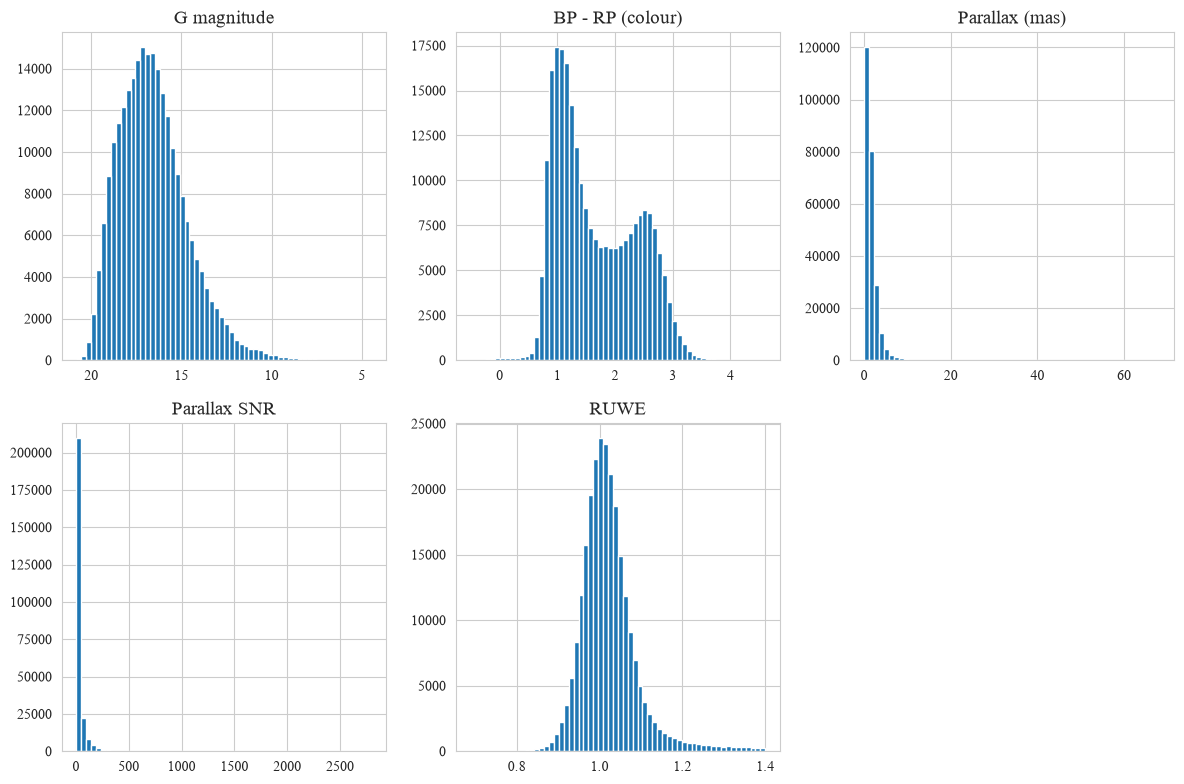

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))

plt.subplot(2,3,1)
plt.hist(df['phot_g_mean_mag'].dropna(), bins=60)
plt.gca().invert_xaxis() # Flips it because dimmer objects have a higher magnitude values and vice versa
plt.title("G magnitude")

plt.subplot(2,3,2)
plt.hist(df['bp_rp'].dropna(), bins=60)
plt.title("BP - RP (colour)")

plt.subplot(2,3,3)
plt.hist(df['parallax'].dropna(), bins=60)
plt.title("Parallax (mas)")

plt.subplot(2,3,4)
plt.hist(df['parallax_snr'].dropna(), bins=60)
plt.title("Parallax SNR")

plt.subplot(2,3,5)
plt.hist(df['ruwe'].dropna(), bins=60)
plt.title("RUWE")

plt.savefig('fig2_raw_parameters.png', dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()

### Interpretations of the above distribution plots
1. `G-magnitude`
  The standard measurement in astronomy works backward. That is why the x-axis was flipped initially `plt.gca().invert_xaxis()`. The axis shows how the stars are distributed from fainter stars (on the left) to brighter stars (on the right). The histogram is skewed Gaia observed vastly more faint stars than bright ones. The plot had central peak of around 14 - 16 as the tails were faint extremes.
2. `bp_rp`
   There is clear bi-modality as there are two peaks, at approx. 1.3 (shows main sequence stars) and another peak at around 2.8 (shows red stars). The main sequence stars are basically just "normal stars" and generally account for 90% of the stars in the universe, hence the higher peak. They are solar type and K-type stars. The second peak indicates cooler red M-dwarfs which are numerous in the Milky Way. 
3. `Parallax`
   This histogram is extremely skewed to the right, skewed towards very low parallax values (below 5 mas). This shows that a vast majority of stars in this dataset are distant with a small number of very nearby stars having measurable/significant parallax.
4. `parallax_snr`
   The distribution of the histogram is extremely skewed to the right, with a massive peak near the origin. This shows that while selected stars have statistically significant parallax measurements (SNR > 5), the majority lie at the lower end of precision due to their great distance. The distant stars (as established above) have small parallaxes with relatively large errors (due to their shifts and since they are very far, large errors are encountered), resulting to an effective small SNR. The tail extends to over 2500 indicating presence of very nearby bright stars thus very tiny error bars. The 'large errors' do not mean that Gaia made a mistake. A nearby star may have a parallax of 100 mas with an error of +/- 0.02. This is a small fraction of the total measurement (small relative error). For a distant star, it may have a parallax of 0.1 mas with an error of +/- 0.02. This accounts for 20% of the total measurement thus a 'larger error' as compared to the previous one (large relative error). This can be concluded by saying that since parallax is an angular measurement which decreases with distance, distant stars have smaller parallax values. However, the instrumental noise is constant making the noise for distant stars to be a huge proportion of the signal leading to large relative errors and smaller SNR.

5. `ruwe`
   The peak is strongly centered at 1.0. This shows that most of the sources in the dataset are well-behaved single stars. The tail extending to the right indicates some sources with poorer astrometric fits, likely binary systems or other complex sources.

### Checking for proper motion scatter and density

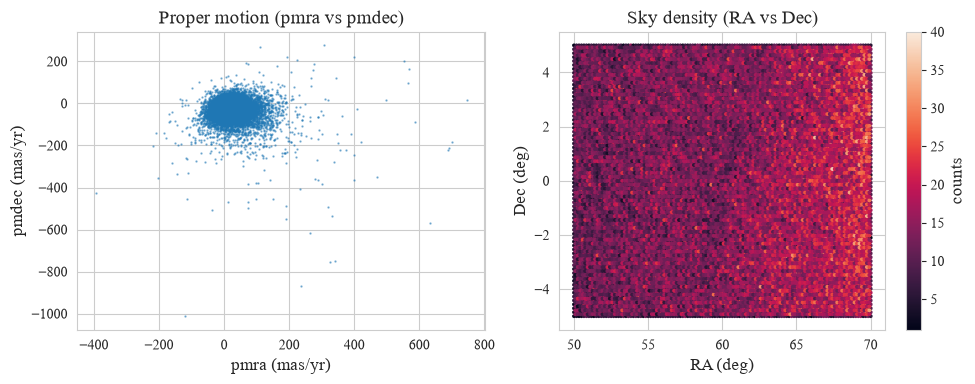

In [9]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.scatter(df['pmra'], df['pmdec'], s=0.5, alpha=0.5)
plt.xlabel('pmra (mas/yr)')
plt.ylabel('pmdec (mas/yr)')
plt.title('Proper motion (pmra vs pmdec)')

plt.subplot(1,2,2)
plt.hexbin(df['ra'], df['dec'], gridsize=120, mincnt=1)
plt.xlabel('RA (deg)')
plt.ylabel('Dec (deg)')
plt.title('Sky density (RA vs Dec)')
plt.colorbar(label='counts')
plt.tight_layout()
plt.show()


### Interpretations of the above distribution plots
1. `Proper motion plot`
   The Blob at (0,0) represents stars that are very far away so they seem barely to move. On the other hand, the scattered plots are nearby stars which have a high proper motion. The scatter plot reveals kinematic structures. The dense blob at (0,0) reveal a distant background stellar population which exhibits minimal apparent motion. The highly dispersed points have high proper motion values and they likely correspond to nearby stars or high velocity objects.
2. `Sky Density Plot`
   This shows the snapshot of the 'sky' that was took by the adql query at the beginning. There are no empty black holes or stripes proving that the data is clean. It gets more red to the right showing a dense area of the Milky Way galaxy. This shows the natural increase in stellar surface density as the line of sight approaches the Galactic plane. 

In [10]:
print ("Total rows:", len(df))
print ("RUWE <= 1.4:", (df["ruwe"] <= 1.4).sum())
print ("parallax_snr >= 5:", (df["parallax_snr"] >= 5).sum())
print ("parallax_snr >= 3:", (df["parallax_snr"] >= 3).sum())
print ("0.8 < phot_bp_rp_excess_factor < 1.4:", ((df["phot_bp_rp_excess_factor"] > 0.8) & (df["phot_bp_rp_excess_factor"] < 1.4)).sum())
# Above phot_bp_rp_excess_factor is extremely precise quality control. If many stars will be lost, I shall keep them.

Total rows: 249295
RUWE <= 1.4: 249295
parallax_snr >= 5: 249295
parallax_snr >= 3: 249295
0.8 < phot_bp_rp_excess_factor < 1.4: 198975


In [ ]:
# FINAL ASTROMETRIC QUALITY FILTERING


print("Starting Gaia quality filtering...")

before_filtering = len(df)

# Calculate the strict quality mask
quality_mask = (
    df["ruwe"].notna() &
    (df["ruwe"] < 1.4) &

    df["parallax"].notna() &
    (df["parallax"] > 0) &

    df["parallax_error"].notna() &
    (df["parallax_error"] > 0) &

    (df["parallax_snr"] > 5)
)

# Display filtering diagnostics before applying the mask
print("Original observations:", before_filtering)

print(
    "Observations with RUWE exactly 1.4:",
    (df["ruwe"] == 1.4).sum()
)

print(
    "Observations failing strict RUWE:",
    (~df["ruwe"].lt(1.4)).sum()
)

print(
    "Observations passing all quality cuts:",
    quality_mask.sum()
)

# Apply quality cuts
df = df.loc[quality_mask].copy()

after_filtering = len(df)

print("-" * 40)
print("QUALITY FILTERING COMPLETE")

print("Before:", before_filtering)
print("After:", after_filtering)
print("Removed:", before_filtering - after_filtering)

# Final validation
assert (df["ruwe"] < 1.4).all()
assert (df["parallax"] > 0).all()
assert (df["parallax_snr"] > 5).all()

print("All strict astrometric quality checks passed.")

In [11]:
df.to_parquet("gaia_subset_raw_snapshot.parquet", index=False)
print ("Saved snapshot:", "gaia_subset_raw_snapshot.parquet")

Saved snapshot: gaia_subset_raw_snapshot.parquet


In [12]:
print((df["astrometric_excess_noise"] > 1.0).sum())
print ((df["astrometric_excess_noise"] <= 1.0).sum())

4256
245039


Before proceeding, the project needed to check the `astrometric_excess_noise`. This is the amount of noise astronomers have to mathematically add to the error budget in order to make the model fit the data. It is basically a diagnostic of how messy Gaia's measurement was. If a captured star was clean, single, not variable and the measurements were consistent, the `astrometric_excess_noise` is approx. zero. If the star is problematic such as binary stars, crowded region, instrument issues etc, Gaia adds extra 'noise' to make the fit acceptable. High `astrometric_excess_noise` will be problematic to this project but doing away with the `4256` stars might hurt the project if they are the project's brightest stars and the ones' that the project need to keep. Brighter stars tend to have a a higher 'instrumental noise'. This is because they saturate the detector pixels slightly. The project proceeded to do a small investigation to check whether the 4256 stars are mainly the bright stars and if they have good metrics, otherwise they get dropped. 

In [13]:
aen_bad = df[df["astrometric_excess_noise"] > 1.0].copy()
print ("High AEN rows:", len(aen_bad))
display (aen_bad[["phot_g_mean_mag", "bp_rp", "parallax", "parallax_snr", "ruwe"]].describe().T)

High AEN rows: 4256


,count,mean,std,min,25%,50%,75%,max
phot_g_mean_mag,4256.0,19.509756,0.445303,17.518570,19.253706,19.544009,19.818857,20.814010
bp_rp,4256.0,2.666095,0.424210,-0.096976,2.509199,2.697867,2.888069,4.178467
parallax,4256.0,3.168552,1.278146,0.923545,2.332554,2.916315,3.667611,18.376961
parallax_snr,4256.0,7.662784,3.879017,5.000036,5.565915,6.461224,8.370810,114.719764
ruwe,4256.0,1.098435,0.075066,0.970927,1.050517,1.080233,1.119829,1.398925


From the summary statistics, it was evident that the stars here were not bright as the `phot_g_mean_mag` was **19.50**. Despite this, a plotwist was encountered. The `bp_rp` mean was **2.66**. These were cool red stars and faint. The excess noise is not from saturation but from possibly the scarcity of photons due to the distance.

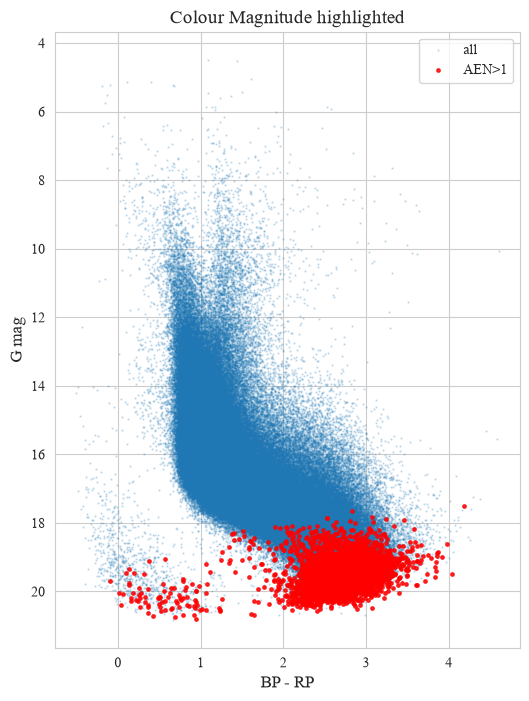

In [14]:
import matplotlib.pyplot as plt
# Investigating using photometry

plt.figure(figsize=(6,8))
plt.scatter(df['bp_rp'], df['phot_g_mean_mag'], s=0.5, alpha=0.2, label='all')
plt.scatter(aen_bad['bp_rp'], aen_bad['phot_g_mean_mag'], s=6, alpha=0.8, c='red', label='AEN>1')
plt.gca().invert_yaxis()
plt.xlabel('BP - RP'); plt.ylabel('G mag'); plt.legend()
plt.title('Colour Magnitude highlighted')
plt.show()

From the above scatter plot, it confirmed that the stars which have a higher `astrometric_excess_noise` are indeed dim. This is because the vast majority of these red stars lie at `G > 18`. The distribution is consistent with the expectation of photon-noise limitation rather than instrinsic contamination.

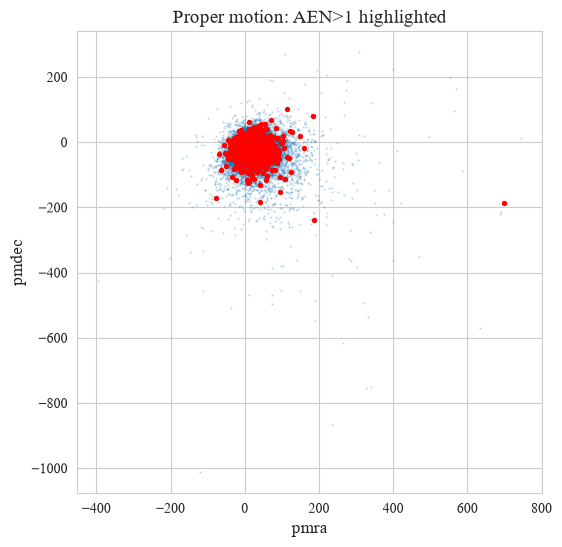

In [15]:
# Investigating using astrometry
plt.figure(figsize=(6,6))
plt.scatter(df['pmra'], df['pmdec'], s=0.5, alpha=0.2)
plt.scatter(aen_bad['pmra'], aen_bad['pmdec'], s=8, c='red')
plt.xlabel('pmra'); plt.ylabel('pmdec'); plt.title('Proper motion: AEN>1 highlighted')
plt.show()

This cemented everything as the scatter plot showed the red blob being at (0,0) indicating that they are consistent with distant background stars. They are very far away and did not appear to move much. If they were a set of intrisically contaminated stars, the scatter plot would depict them everywhere/scattered. They behave the same as the previous photometry plot. Combined with their acceptable `RUWE` values, the project confirmed that the excess noise was as a result of their faint magnitude (**G > 18**) rather than astrometric instability. The project retained the stars.

## Exploratory Data Analysis
### Phase 1: Raw Observables
Here the project was to explore the directly observed Gaia DR3 quantities, that is the photometric and astrometric measurements before any transformation. The goal was to assess the distributions of the raw signals produced. Fortunately, this was also 'done' at the `diagnostic` stage as the project attempted to investigate potential issues that were not filtered at the query stage.

### Plot 1: Showing the distribution of Gaia G-band Apparent Magnitudes

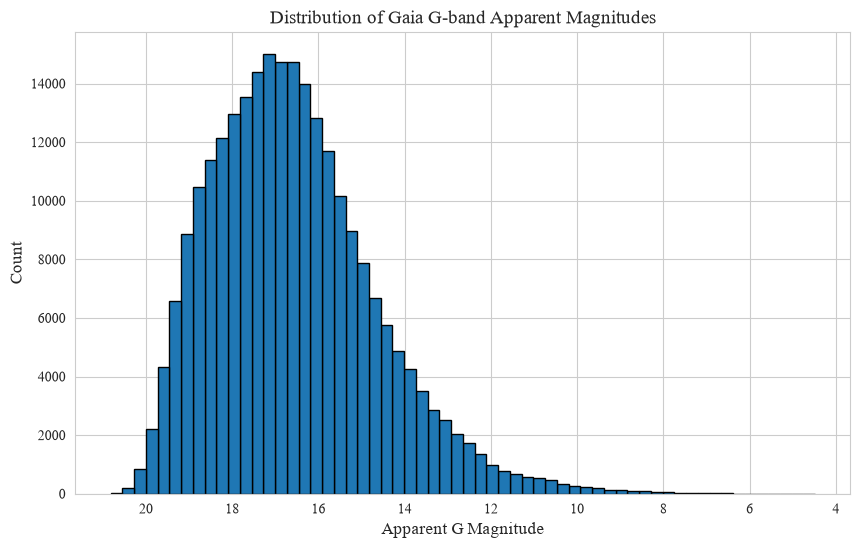

In [16]:
plt.figure(figsize=(10,6))
plt.hist(df["phot_g_mean_mag"].dropna(), bins=60, edgecolor='black')
plt.gca().invert_xaxis()  # magnitude scale: dimmer = left
plt.xlabel("Apparent G Magnitude")
plt.ylabel("Count")
plt.title("Distribution of Gaia G-band Apparent Magnitudes")
plt.show()

#### Interpretation/Discussion
The histogram showed that most stars in the selected region are faint as confirmed earlier on. There was a strong concentration between G 16 to 18 mag. Gaia detects a large number of distant stars compared to a much smaller number of intrinsically bright or nearby stars. The left side shows the dimmer stars as it tends to brighter stars on the right. Astronomical magnitude decreases with an increase in brightness.

### Plot 2: Showing the BP-RP colour distribution

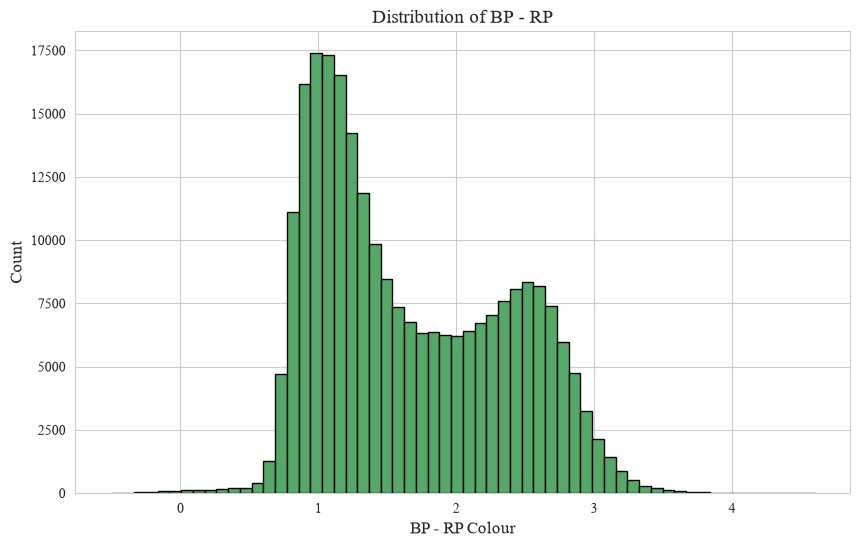

In [17]:
plt.figure(figsize=(10,6))
plt.hist(df["bp_rp"].dropna(), bins=60, color="#55A868", edgecolor="black")
plt.xlabel("BP - RP Colour")
plt.ylabel("Count")
plt.title("Distribution of BP - RP")
plt.show()

#### Interpretations/Discussion
The `bp_rp` histogram shows a bi-modal structure indicating two sistinct stellar populations. The first peak is between 0.9 to 1.4. As discussed before, they are the main sequence stars which account to 90% of the stars as they are detectable. The second peak is around 2.3 to 2.8. They represent the red giant branch as well as cool M-dwarfs both of which are red. Although the red giant are less common, their luminosity makes them detectable at large distances. The absence of a significant portion of blue stars (bp_rp < 0.5) is expected as they are hot stars and rare and typically found in young clusters, not in random sky patches.

### Plot 3: Showing Parallax distribution (mas) - Distance indicator

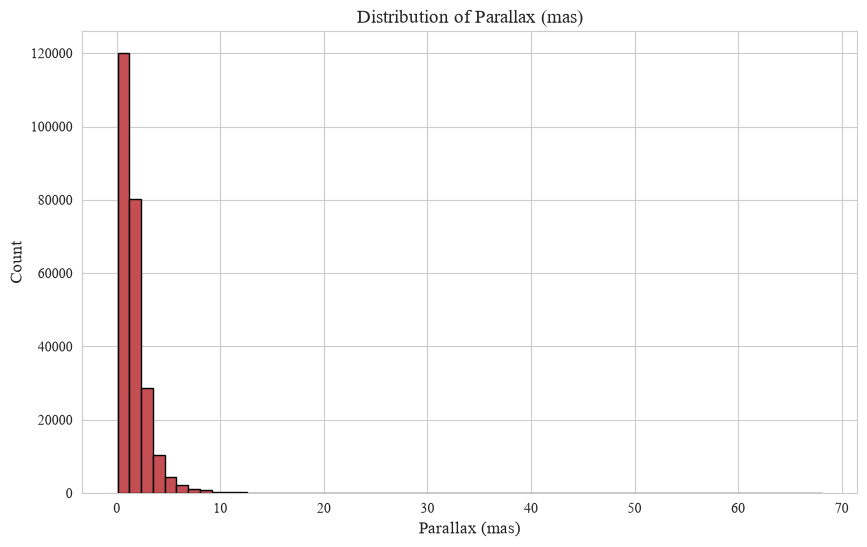

In [18]:
plt.figure(figsize=(10,6))
plt.hist(df["parallax"].dropna(),bins=60, color="#C44E52", edgecolor="black")
plt.xlabel("Parallax (mas)")
plt.ylabel("Count")
plt.title("Distribution of Parallax (mas)")
plt.show()

#### Interpretations/Discussions
Most stars are seen to be very far away as the distribution is strongly skewed to the right. There is a peak near/below 1 mas and a small number of nearby stars with parallax > 5. The earlier query ensured `parallax > 0` as well as `parallax_error/parallax < 0.2` making the parallaxes to be meaningful.

### Plot 4: Showing parallax SNR distribution

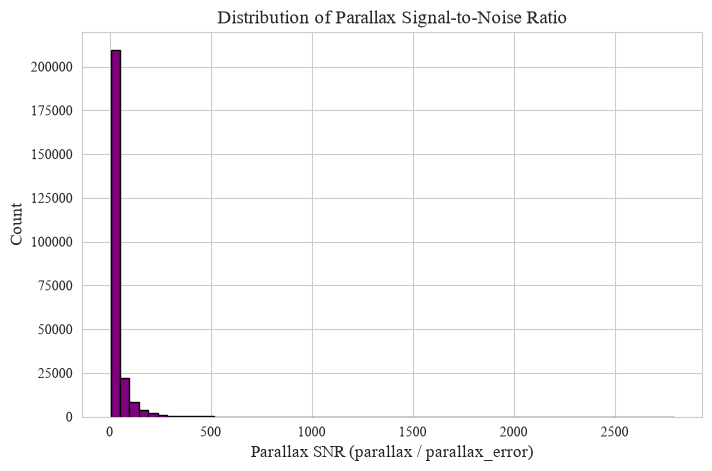

In [19]:
plt.figure(figsize=(8,5))
plt.hist(df["parallax_snr"].dropna(),bins=60, color="purple", edgecolor="black")
plt.xlabel("Parallax SNR (parallax / parallax_error)")
plt.ylabel("Count")
plt.title("Distribution of Parallax Signal-to-Noise Ratio")
plt.show()

#### Interpretations/Discussions
The distribution of the histogram is extremely skewed to the right, with a massive peak near the origin. This shows that while selected stars have statistically significant parallax measurements (SNR > 5), the majority lie at the lower end of precision due to their great distance. The distant stars (as established in `plot 3`) have small parallaxes with relatively large errors (due to their shifts and since they are very far, large errors are encountered), resulting to an effective small SNR. The tail extends to over 2500 indicating presence of very nearby bright stars thus very tiny error bars. The 'large errors' do not mean that Gaia made a mistake. A nearby star may have a parallax of 100 mas with an error of +/- 0.02. This is a small fraction of the total measurement (small relative error). For a distant star, it may have a parallax of 0.1 mas with an error of +/- 0.02. This accounts for 20% of the total measurement thus a 'larger error' as compared to the previous one (large relative error). This can be concluded by saying that since parallax ia an angular measurement which decreases with distance, distant stars have smaller parallax values. However, the instrumental noise is constant making the noise for distant stars to be a huge proportion of the signal leading to large relative errors and smaller SNR.

In [20]:
print (df["parallax_snr"].describe())

count    249295.000000
mean         33.367412
std          61.203889
min           5.000011
25%           7.967188
50%          14.253358
75%          32.843852
max        2795.493344
Name: parallax_snr, dtype: float64


Since the above plot of `parallax SNR distribution` was heavily skewed, the project proceeded to plot one whose x-axis has been log scaled. This is because from the above summary statistics, the range between the minimum to the maximum was quite huge. A logarithmic x-axis would:
1. Spread out the low SNR region (say 5 to 50) which contains most stars.
2. Compress the extremely large SNR values (say from 100 to 2795) without distorting them.
3. Makes us have the true shape of the data.

### Parallax SNR distribution with log scale

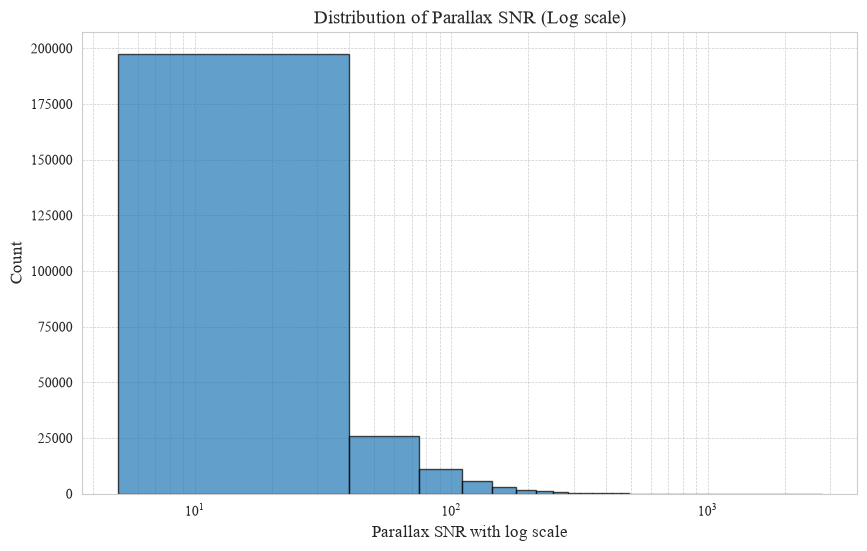

In [21]:
plt.figure(figsize=(10,6))
plt.hist(df["parallax_snr"], bins=80, edgecolor="black", alpha=0.7)
plt.xscale("log")
plt.xlabel("Parallax SNR with log scale")
plt.ylabel("Count")
plt.title("Distribution of Parallax SNR (Log scale)")
plt.grid(True, which="both", ls="--", linewidth=0.5)
plt.show()

After applying a logarithmic x-axis, the plot was well spread leading to a true revelation of the `parallax SNR distribution`. The first few bins contain the majority of the stars as they dominate the plot. This is as a result of Gaia sources having low to moderate parallax precision. As X increases the bars became smaller and smaller as close bright stars are rare. The log scale indeed spread the data across the several orders of magnitude and exposes the tru structure of the distribution

The project proceeded to plot another histogram which expands on the stars whose SNR is less than 100 (10²). This was to give a better understanding on how the stars are spread along the left region of the histogram. The project restricted the `parallax_snr` to < 100.

### Parallax SNR distribution clipped at less than 100

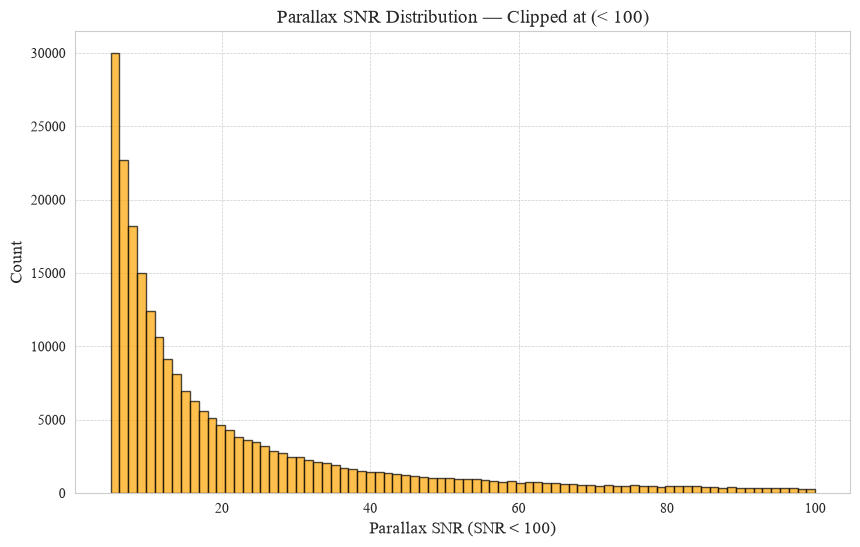

In [22]:
plt.figure(figsize=(10,6))
plt.hist(df[df["parallax_snr"] < 100]["parallax_snr"], bins=80, color="orange", edgecolor="black", alpha=0.7)
plt.xlabel("Parallax SNR (SNR < 100)")
plt.ylabel("Count")
plt.title("Parallax SNR Distribution — Clipped at (< 100)")
plt.grid(True, ls="--", linewidth=0.5)
plt.show()

The zoomed in view confirmed that lower SNR values dominate the sample as it was evident from the recent summary statistics. The restricted histogram provides a clear picture that was otherwise compressed to a single bar on the initial `parallax SNR distribution`.

### Plot 5: Showing the RUWE distribution

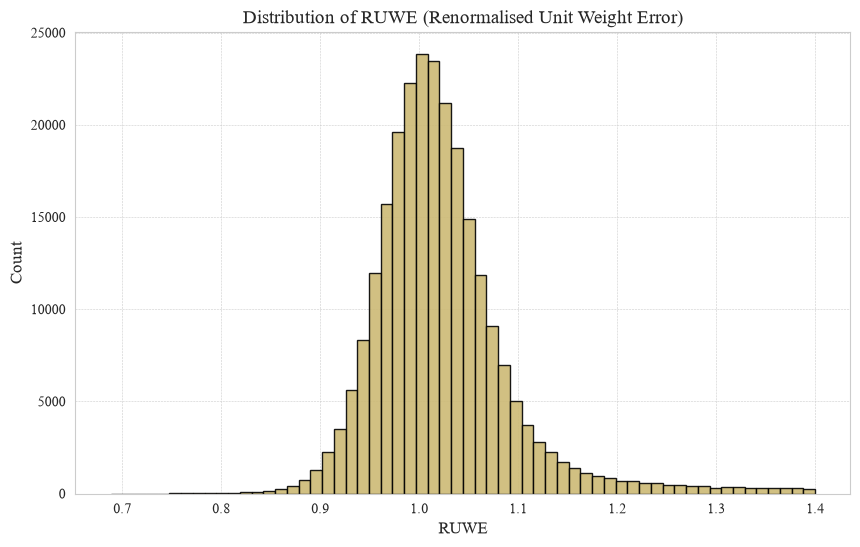

In [23]:
plt.figure(figsize=(10,6))
plt.hist(df["ruwe"].dropna(), bins=60, color="#CCB974", edgecolor="black", alpha=0.9)
plt.xlabel("RUWE")
plt.ylabel("Count")
plt.title("Distribution of RUWE (Renormalised Unit Weight Error)")
plt.grid(True, which="both", ls="--", linewidth=0.4)
plt.show()


#### Interpretation/Discussion
RUWE measures whether the Gaia astrometric solution (position, parallax, motion) fits the observation well. It ensures that clustering is based on clean stellar motions not wobbling binaries. This is basically the astrometric fit quality. For a good astrometric fit, the RUWE needs to be approximately 1. From our plot, most stars had a RUWE of around 1.0 with a short tail towards higher values. The project's adql query at the beginning restricted the RUWE to 1.4. This was because any value above that shows the stars are problematic in the sense that they may be binary stars not modelled correctly, callibration issues, problematic observations among others.

### Plot 6: Showing the Proper Motion distribution (Raw physical distribution)

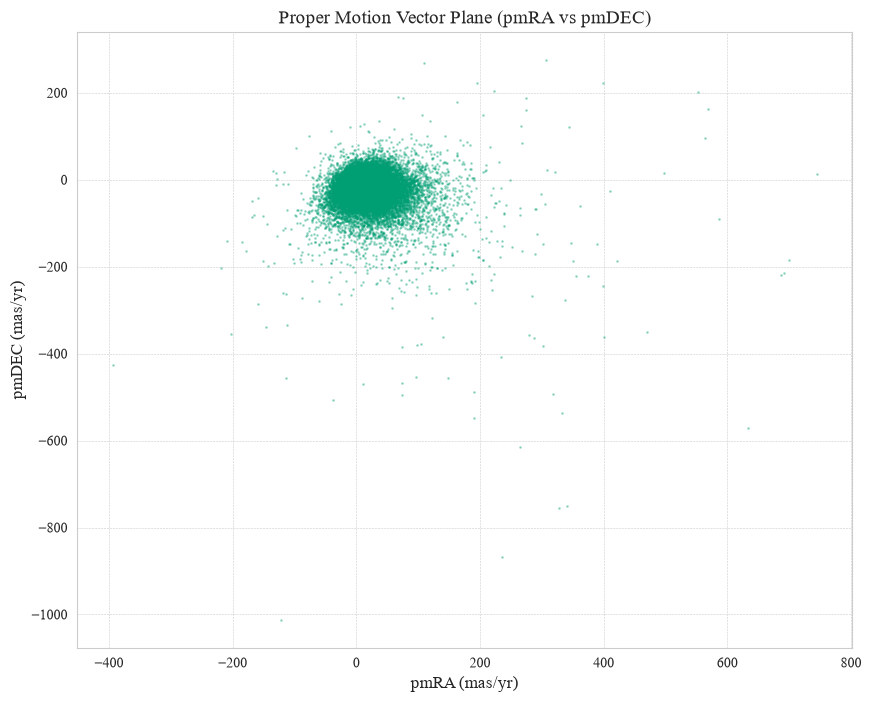

In [24]:
plt.figure(figsize=(10, 8))
plt.scatter(df["pmra"], df["pmdec"], s=1, alpha=0.3, color="#009E73")
plt.xlabel("pmRA (mas/yr)")
plt.ylabel("pmDEC (mas/yr)")
plt.title("Proper Motion Vector Plane (pmRA vs pmDEC)")
plt.grid(True, linestyle="--", linewidth=0.4)
plt.show()

#### Interpretations/Discussions
The Blob at approximately (0,0) represents stars that are very far away so they seem barely to move. On the other hand, the scattered plots are nearby stars which have a high proper motion. The scatter plot reveals kinematic structures. The dense blob at (0,0) reveal a distant background stellar population which exhibits minimal apparent motion. The highly dispersed points have high proper motion values and they likely correspond to nearby stars or high velocity objects.

### Showing the Proper motion distribution with Log axes
This was done to reveal hidden structures in the blob.

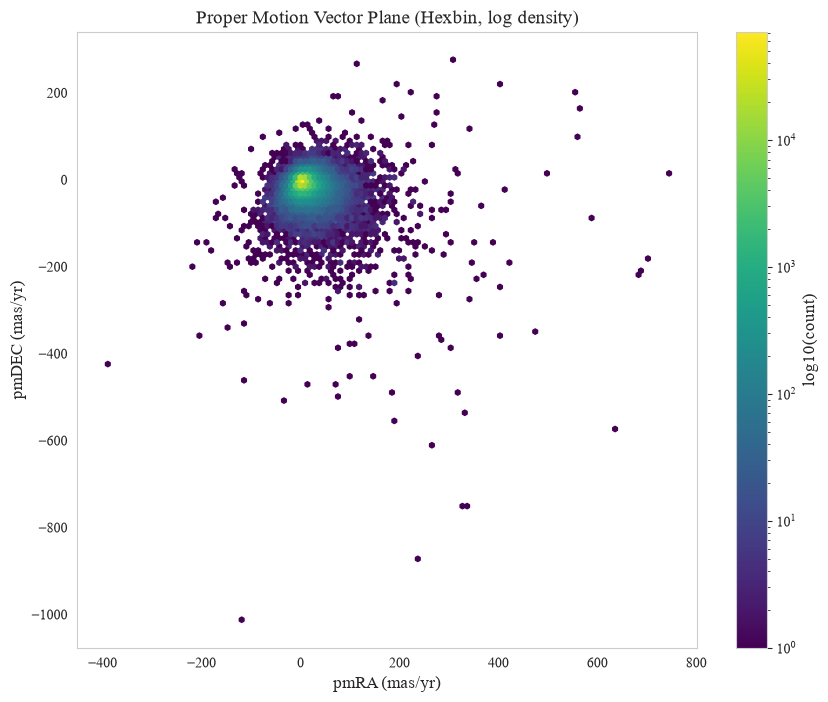

In [25]:
plt.figure(figsize=(10, 8))
plt.hexbin(df["pmra"], df["pmdec"], gridsize=120, mincnt=1, bins="log",cmap="viridis")
plt.xlabel("pmRA (mas/yr)")
plt.ylabel("pmDEC (mas/yr)")
plt.title("Proper Motion Vector Plane (Hexbin, log density)")
cb = plt.colorbar()
cb.set_label("log10(count)")
plt.grid(False)
plt.show()

#### Interpretations/Discussions
The plot showed the sub structures inside the blob (approx. 0,0). A dense circular concentration centred at (0,0) shows that majority of stars have very  small proper motions, consistent with distant background stars whose apparent motion is minimal. This group dominated the dataset by magnitude of 10^4. Surrounding this core is a diffuse halo of stars exhibiting moderately larger motions representing nearby stars and local moving groups. The scattered extreme outliers correspond to genuine high proper motion stars typically nearby objects or high velocity halo stars. The log scaled density colour map highlights differences spanning several orders of magnitude allowing the inner structure of the proper motion distribution to become visible.

### Feature Engineering: Deriving physical stellar quantities
Certain astrophysical analyses, most notably the Hertzsprung-Russell diagram require derived quantities such as distance and absolute magnitude. The HR diagram is the 'Holy Grail' visualization of this project. The quantities to be converted do not appear directly in our attributes and must be computed from the raw observables.

In [26]:
from astropy import units as u
from astropy.coordinates import SkyCoord
import numpy as np
# 1. Distance (parsecs) - assumption is High SNR parallax aloows for direct inversion; low parallax would be problematic to invert
# d-pc = 1000/parallax
df["distance_pc"] = 1000.0 / df["parallax"]

# 2. Absolute Magnitude (M_G)
# M_G = Mg + 5 - 5log10(d_pc)
df["abs_g_mag"] = df["phot_g_mean_mag"] + 5 - 5 * np.log10(df["distance_pc"])

#3. Total proper motion (mas/yr) - this is by 
#combining RA and DEC motion into a single magnitude of motion
# pm_tot= squareroot(pmra^2 + pmec^2)
df["pm_total"] = np.sqrt(df["pmra"]**2 + df["pmdec"]**2)

#4. Tangential velocity
# V_tan = 4.74 x pm_tot(arcsec/yr) x d_pc
# pm_tot is divided by 1000 as it is in mas/yr to get arcsec
df["tangential_velocity"] = 4.74 * (df["pm_total"] / 1000.0) * df["distance_pc"]

# 5. Cartesian coordinates (X, Y, Z) for clustering
# Since space is curved, there was need to convert the angles on the sky (RA/Dec) to XYZ (Cartesian)
# astropy does this very well as this is complex trigonometry 
c = SkyCoord(
    ra = df["ra"].values * u.degree, #astropy is very strict as it needs one to specify if it is in degrees or radians
    dec = df["dec"].values * u.degree,
    distance = df["distance_pc"].values * u.pc
)
# Calculating into coordinates (cartesian)
df["x"] = c.cartesian.x.value 
df["y"] = c.cartesian.y.value
df["z"] = c.cartesian.z.value

print ("Feature Engineering complete.")
display(df[["abs_g_mag", "tangential_velocity", "x", "y", "z"]].describe().T)


Feature Engineering complete.


,count,mean,std,min,25%,50%,75%,max
abs_g_mag,249295.0,7.119692,2.624079,-3.429548,5.120238,6.879671,9.182466,16.551900
tangential_velocity,249295.0,46.820249,39.303066,0.037390,23.967667,38.287956,57.766887,707.157891
x,249295.0,475.913671,358.932006,6.345727,228.486217,377.422212,622.437524,7555.467114
y,249295.0,868.537139,649.824485,12.413493,416.920387,687.392639,1144.749068,10190.605287
z,249295.0,-0.651922,62.323924,-837.906959,-30.234115,-0.373840,29.437562,734.890186


#### Interpretations/Discussions
The project proceeded to have an upgrade to Astrophysics.

1. Distance (parsecs) - `distance_pc`
   
   The standard formula for parallax distance is $d = 1/\varpi$, where $\varpi$ is in arcseconds. Gaia provides parallax in milliarcseconds (mas). To now convert units: 1 mas = 0.001 arcsec. Therefore, $d = 1 / (0.001 \times \varpi_{mas}) = 1000 / \varpi_{mas}$. The derived distances range from very close solar neighbour to distant ones.
2. Absolute magnitude (`abs_g_mag`)
 
   The formula:
    $$M_G = m_G + 5 - 5 \log_{10}(d_{pc})$$
   converts the apparent magnitude (`phot_g_mag`) which is how bright it looks to absolute magnitude which is how bright it actually is if placed at 10 parsecs. The minimum of -3.4 represents highly luminous stars. The mean of 7.1 represents a fainter star than the sun. The sun has $M_G$ of 4.8. The maximum 16.55 represent the faint red dwarfs we observed earlier on.
3. Total Proper motion (`pm_total`)
   
   Total proper motion is the length of the star's motion vector across the sky. This explains how fast the star appears to move on angular units (mas/yr) independent of direction. Gaia measures how stars move across the sky overtime by using two components, `pmra` and `pmdec`, horizontal and vertical respectively. A star can move diagonally depending on how the two components combine. Combining them informs us how fast a star moves and not just their direction. `pmra` and `pmdec` only tells us the direction. The true angular speed is given by:
   $$\mu = \sqrt{(\text{pmRA})^2 + (\text{pmDEC})^2}$$
   This is the total proper motion. This answers the question, how fast does the star move across the sky regardless of direction?
   A higher $\mu$ - `Total proper motion`, the more likely that the star is closer or it is just a high velocity star. Total proper motion is important as it is used to compute `tangential velocity` which is now the real space speed as explained below.  
   
5. Tangential Velocity (`tangential_velocity`)
   
   The formula:
    $$v_{tan} \approx 4.74 \times \mu_{total} \times d_{pc}$$
   converts angular proper motion (mas/yr) to physical speed (km/s). It is simply the actual speed of the star in km/s. The constant 4.74 is the unit conversion constant reLation to parsecs, years and kilometres. The mean of 46.82 aligns solidly with expected stellar velocity dispersion in the Milky Way's thin disk (30 - 50 km/s). Most stars are seen to move in an orderly fashion. The max of 707.15 is an outlier or shows the presence of a high velocity stars such as Halo Stars that have been ejected from binary systems. These stars are physically distinct from the disk population. Tangential velocity is important because `pmra` and `pmdec` is biased by distance in the sense that a nearby star appears to move very fast compared to a far away star which appears to move slowly (due to its distance) although it might have a higher velocity. Tnagential velocity is fair as it allows one to compare the actual speed of a star at 100pc with a star at 1000pc
6. Cartesian coordinates

    The project used `astropy.coordinates.SkyCoord` to perform the transformation from spherical to Cartesian notation. The reasoning behind this is K-means and other algorithms struggle with spherical coordinates. This is because 359° is next to 0°. K-means calculates Euclidean distance and it fails on spherical coordinates. Converting to a 3D box creates a continuous space for the algorithm. It is evident that the range of the Z-axis is much smaller as compared to the rest. This is due to the query selected at the beginning especially the `dec (-5° and 5°)`. Since this is almost flat along the equator, the spread of Z is natuarally small.
   

### Phase 2: EDA on Derived physical quantities
Having the derived features available, the project examines the astrophysical structure of the sample. This includes the earlier mentioned Hertzsprung-Russell diagram analyzing the stars' behaviour.

### Plot 1: The Hertzsprung-Russell (HR) Diagram

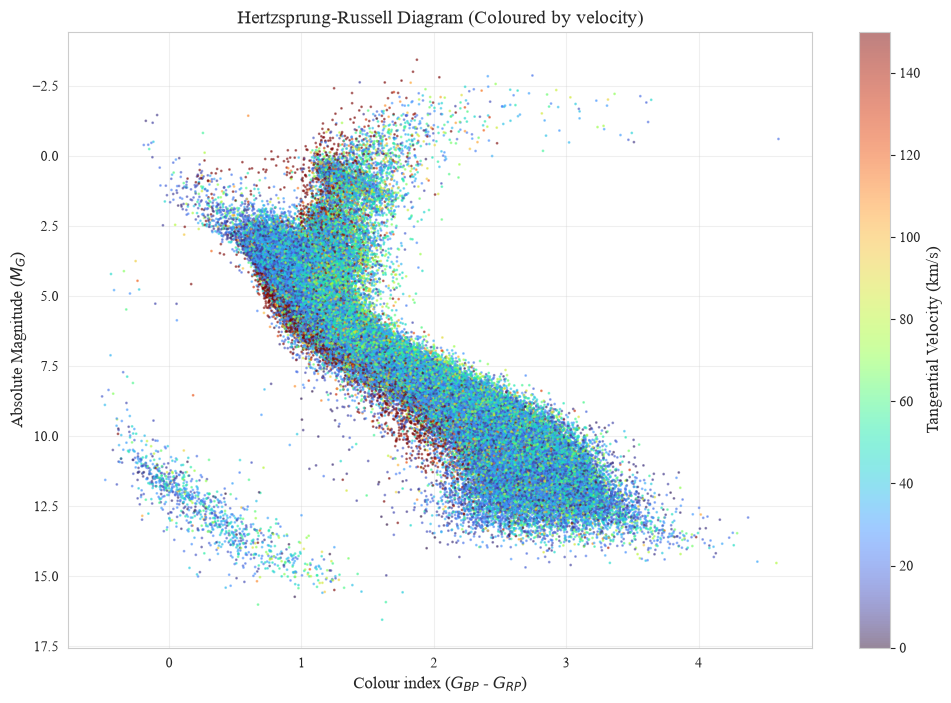

In [27]:
plt.figure(figsize=(12,8))
# The scatter plot is colour against absolute magnitude

sc = plt.scatter(df["bp_rp"], df["abs_g_mag"], s=1, alpha=0.5, c=df["tangential_velocity"], cmap="turbo", vmin=0, vmax=150)
# c=df["tangential_velocity"] adds a 3rd dimension to the plot whereby instead of 
# making the dots black, the colour is determined by how fast the star is moving.

# vmin=0, vmax=150 clamps the colour scale. This is because there is presence of an outlier star
# moving at 707km/s. If the scale was left from 0 to 700km/s, there wouldn't be any difference between
# a 30 km/s star(normal star) and a 60km/s star (slightly fast star)

plt.gca().invert_yaxis()
plt.xlabel("Colour index ($G_{BP}$ - $G_{RP}$)")
plt.ylabel("Absolute Magnitude ($M_G$)")
plt.title("Hertzsprung-Russell Diagram (Coloured by velocity)")
#colorbar
cbar = plt.colorbar(sc)
cbar.set_label ("Tangential Velocity (km/s)")

plt.grid(True, alpha=0.3)
plt.savefig('fig3_HR_diagram.png', dpi=300, bbox_inches='tight')
plt.show()

#### Interpretations/Discussions
The derived absolute magnitudes ($M_G$) and colour indices ($G_{BP}$ - $G_{RP}$) were utilized to construct the Hertzsprung-Russell diagram coloured by tangential velocity.
1. The plot reveals a distinct 'Main Sequence" running diagonally from top left. This dominant diagonal feature represents the hydrogen-burning main sequence ranging from luminous ($M_G$ approx. 0) blue stars ($G_{BP}$ - $G_{RP}$ approx. 0) to faint M-dwarfs ($M_G$ > 12). The compactness of the sequence validates the accuracy of the parallax-derived distances. 90% of the stars follow this trend including the sun. The blue stars on the top left of the main sequence are large, hot and burn brightest. The main sequence gets dimmer as it goes down to the bottom right towards the bottom red stars. This is because gravity crushing the star inwards with its radius, so larger stars have to generate more outward pressure to prevent collapse. Stars spend most of their time fusing hydrogen into helium in their cores. Stars that fuse hydrogen faster will be hotter because they are making more energy. The role of fusion depends on the pressure in a star's core. More massive stars squeeze their cores' harder so they fuse faster and get hotter than low mass stars.
2. A distinct population evolves off the main sequence towards the top right. They are the red giant branch ($G_{BP}$ - $G_{RP}$ approx. 1.5, $M_G$ < 2), representing evolved stars into giants. They are luminous but cool. They are part of the dying process of stars like the sun. Above them are red super giant massive stars which are beginning their death stage.
3. There is a white dwarf sequence, which us a separate faint population which is visible at the bottom left ($G_{BP}$ - $G_{RP}$ approx. < 1.0, $M_G$ > 10). They are hot degenerate stellar remnants. They are very faint. They are the result of a star like the sun eventually running out of hydrogen fuel. The sun will become a red giant in 5 billion years and eventually a white dwarf.

The colour mapping revealed a kinematic correlation between position on the HR Diagram and tangential velocity. The majority of the Main sequence stars exhibit low velocities (< 50km/s, blue/cyan) consistent with membership in the galactic Thin Disk. Alternatively, stars with higher tangential velocity (> 80 km/s, orange/red) are preferrentially found on the Sub-dwarf region (below the main sequence) or the broad background , indicative of Thick Disk or Halo populations which possess higher velocity.

In general, the project established:
* In the main sequence, there are:
    * Blue stars (O-type, B-type): big, hot and bright (3 to 60 solar masses)
    * Yellow stars (F-type, G-type): in between (close to 1 solar mass)
    * Red stars (M-type): small, cool, dim (down to 0.1 solar mass)
* Beyond the main sequence, there are red giants and white dwarfs;
    * Red giants: red and cool (0.8 - 8 solar masses)
    * White dwarfs: tiny and hot (0.5 - 1.3 solar masses)

  Mass does not determine whether a star is a 'dwarf' or a 'giant'. The radius and internal structure do. Giants have massive radii while dwarfs have smaller ones. A red giant of 0.8 solar mass is very much bigger than a white dwarf of 0.5 solar mass. They differ in size completely. Red giants have a low density because the hydrogen in their core is exhausted and the outer envelope expands dramatically, a balancing act of pressure and gravity. White dwarfs have a very high density. This is because the core collapses into a very compact object as it ejects its outer layers (planetary nebula phase).
      
The above (main sequence, Red giant and White dwarfs) are the 3 most dominant visible classes of stars. Most of the stars that have existed on the past and most of the stars that exist today fall into one of these categories but they are not static. They will move across these categories over time as explained by our sun above. 

### Plot 2: Tangential velocity distribution

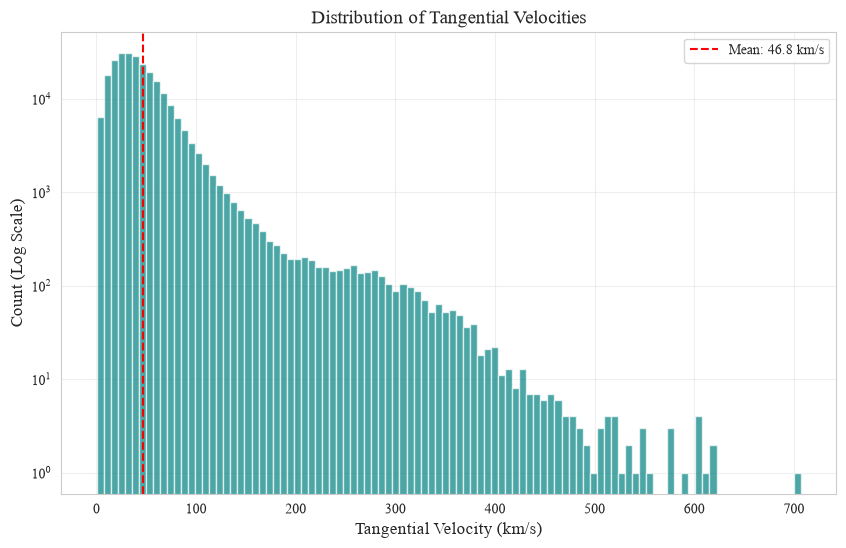

In [28]:
plt.figure(figsize=(10, 6))

# Ploting histogram with Log Scale on Y-axis. This is to well see the very fast stars
plt.hist(df['tangential_velocity'], bins=100, color='teal', alpha=0.7, log=True)

plt.xlabel('Tangential Velocity (km/s)')
plt.ylabel('Count (Log Scale)')
plt.title('Distribution of Tangential Velocities')
plt.grid(True, alpha=0.3)
# Adding a vertical line for the mean
plt.axvline(df['tangential_velocity'].mean(), color='red', linestyle='--', label=f"Mean: {df['tangential_velocity'].mean():.1f} km/s")
plt.legend()
plt.savefig('fig4_tangential_velocity.png', dpi=300, bbox_inches='tight')
plt.show()

#### Interpretations/Discussions
The distribution was skewed as it had a long tail to the right. This is exactly how stellar velocities behave in the galaxy. There was a peak at around 30-50km/s. That confirmed that the majority of the stars (as suggested by the HR Diagram) belong to the thin disk (calm, orderly traffic of the Milky Way).Beyond the peak, the histogram displayed a gradual decline extending to the 80 -120km/s range. This intermediate velocity trail corresponds thick disk, chemically older population with higher velocity dispersion. The tail bars extended to the 200 - 400km/s regions. These stars possess much larger random motions. They represent Halo stars. At the extreme end, the tail was characterized with a tiny blip at 700km/s (707 km/s as evidenced by summary statistics) showing that the plot captured the hyper velocity stars. 
The use of a logarithmic y-axis was essential as without it, the high velocity rail would be visually compressed making halo stars effectively invisible. The resulting plot gave a clear, physically accurate breakdown of the Galaxy's major kinematic components.

### Plot 3: Tangential Velocity vs Colour

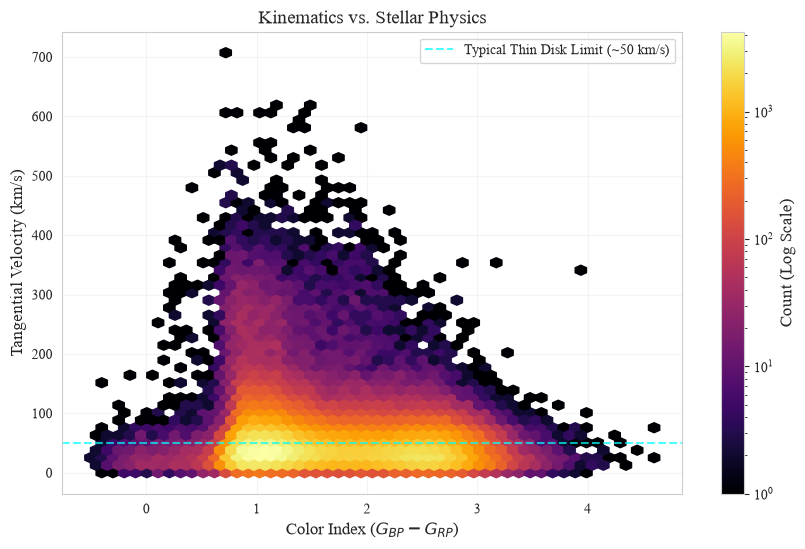

In [29]:
plt.figure(figsize=(10, 6))
# Used a Hexbin plot because we have so many points.
# Scatter plots would just look like a solid blob.
hb = plt.hexbin(df['bp_rp'], df['tangential_velocity'], 
                gridsize=50, cmap='inferno', bins='log', mincnt=1)

plt.colorbar(hb, label='Count (Log Scale)')
plt.xlabel('Color Index ($G_{BP} - G_{RP}$)')
plt.ylabel('Tangential Velocity (km/s)')
plt.title('Kinematics vs. Stellar Physics')
plt.grid(True, alpha=0.2)
# Adding a "soft limit" line where most Thin Disk stars live
plt.axhline(50, color='cyan', linestyle='--', alpha=0.7, label='Typical Thin Disk Limit (~50 km/s)')
plt.legend()
plt.savefig('fig_reserve_hexbin.png', dpi=300, bbox_inches='tight')
plt.show()

#### Interpretations/Discussions
From the plot, it was seen that there was a bright yellow/orange band concentrated at the bottom of the plot,typically below 50km/s. This showed that regardless of colour (from blue to red stars), the vast majority of stars have low tangential velocities as also seen from the `tangential velocity histogram`. This confirmed that the sample was dominated by the Galactic thin disk. These stars, including our sun do orbit the galactic centre in a relatively calm orderly plane. In other words, gravity has not yet affected their orbits significantly.

On the left of the X-axis, ($G_{BP} - G_{RP}$ < 0.8), there are very few stars with a velocity greater than 100km/s as the majority of them had a velocity of approximately 50km/s. These majority were blue stars which were young (in astronomical terms). Due to the fact that they were born recently, they had not yet interacted with massive galactic structures that would scatter them in high speed orbits. They retain the calm motion of the gas clouds they were born from.

Moving to the right, (($G_{BP} - G_{RP}$) > 0.8), most stars remain in the yellow-orange region although there were significant sprays of purple outliers reaching velocities of 200 to 400km/s. This explained that redder stars (actually yellow/orange) are generally older as they have interacted with massive galactic structures. They were gravitationally kicked by by passing masses thus increasing in random velocities. A possible outlier was seen having a velocity of over 700km/s. This may have been a part of a binary star whose partner went supernova and got slingshotted, or it wandered too close to a Black Hole. Since it had a colour of approx. 0.8 and an extreme velocity of over 700km/s, Machine Learning (to be done) would not assign it to a normal disk but to a halo/outlier cluster. 

As expected, $G_{BP} - G_{RP}$ > 2.8 which are red stars would have high velocities as they are older stars but as per the plot, it was the opposite. The plot established a similarity of speeds between the young blue stars and these red old (expected to be old) stars. It was expected for these red stars, having lived for billions of years, to get slingshotted around and become fast. The reason behind the red stars not having high velocities was because of the location the data came from. The data of these stars came from the Orion/Taurus region. In these region, there were other types of stars that were extremely red. They are called **The Newborn**. The dataset covered the **`Taurus-Auriga`** and **`Orion`** regions which are famous **Star forming regions**. When a star is just born, this Young Stellar Object is often wrapped by a blanket of dusty gas. The Red disguise is the dust which blocks the blue light and lets the red light through (similar to the sunset). This is what eventually made the baby stars to be extremely red ($G_{BP} - G_{RP}$ > 2.8). Since they were just born from a gas cloud, they still moved at the same slow calm speed as the cloud. There was also a possibility of selection bias whereby stars with $G_{BP} - G_{RP}$ > 3 are M-dwarfs which are incredibly faint. This is due to their distance. Gaia only captured M-dwarfs which were near and effectively missed out on the fast 'Halo' M-dwarfs because they were too far/dim for the telescope to see thus despite calculating `tangential_velocity`, it could not tell the fast ones. Gaia truly captured red M-dwarfs which are old but only the ones that were near to us. The only way to distinguish `The Newborns` and `M-dwarfs` is through the HR Diagram. M-dwarfs were at the bottom right of the main sequence while the Newborns, sat above the Main Sequence. This is because they are huge and brighter than a normal M-dwarf.

The plot validated the inclusion of `Tangential Velocity` as a clustering feature. It demonstrated that velocity is not random but correlated with the stellar type. By clustering both physics (colour) and kinematics (velocity), there would be a separation of the Young Thin Disk (Blue/slow) from the Old Thick disk/Halo (Red/fast).

### Plot 4: The Spatial Map (The Geometry)

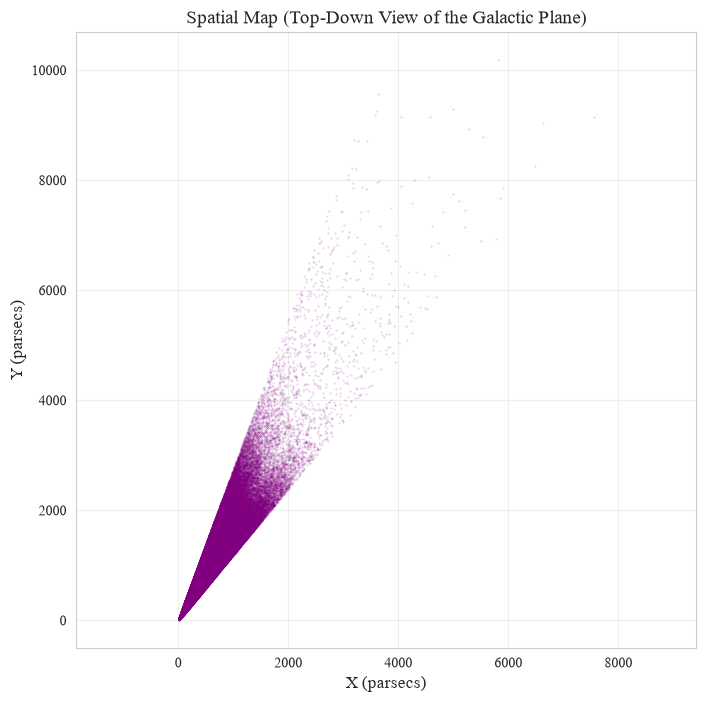

In [30]:
plt.figure(figsize=(8, 8))

# Scatter plot: X vs Y
# 's=0.1' makes the points tiny dust motes
# 'c=purple' is just a stylistic choice
plt.scatter(df['x'], df['y'], s=0.1, alpha=0.3, c='purple')

plt.xlabel('X (parsecs)')
plt.ylabel('Y (parsecs)')
plt.title('Spatial Map (Top-Down View of the Galactic Plane)')
# CRITICAL: 'equal' aspect ratio
# This forces 100 parsecs on X to look the same size as 100 parsecs on Y.
# Without this, the plot would be stretched and misleading.
plt.axis('equal')
plt.grid(True, alpha=0.3)
plt.savefig('fig1_SpatialMap.png', dpi=300, bbox_inches='tight')
plt.show()

#### Interpretation/Discussion
To conlude phase 2 of EDA, the project proceeded to plot the geometry of the data. This plot showed a 3D physical location of the stars in the Milky Way Galaxy. It explained where they float in the 3D void of space relative to the sun/earth. The plot revealed three critical stuff about the dataset.
1. The formation of the 'cone shape'confirmed the coordinate transformation math earlier on (RA/Dec to X/Y/Z) worked. Otherwise, it would have looked like a blob.
2. Towards the origin (earth's position) the plot is characterized by a dense purple colouring as it fades outwards. It clearly showed how the Gaia telescope (or all telescopes for that matter) work. As distance increases the telescope only sees super bright giant stars. Faint dwarfs are missed out. This thinning out is an astronomy bias called Malmquist Bias.
3. There was no presence of holes in the cone proving that Gaia captured the region uniformly.

The characteristic cone resulted from the projection of the earlier selected square field of view (RA 50°-70°) extending outward from the sun. The decreasing stellar density at larger distances (d > 2000pc) illustrated the magnitude limited nature of the survey (Malmquist Bias) where highly luminars stellar objects remain detectable at the survey's edge.

The plot below showed the side view incorporating declination ('z-axis')

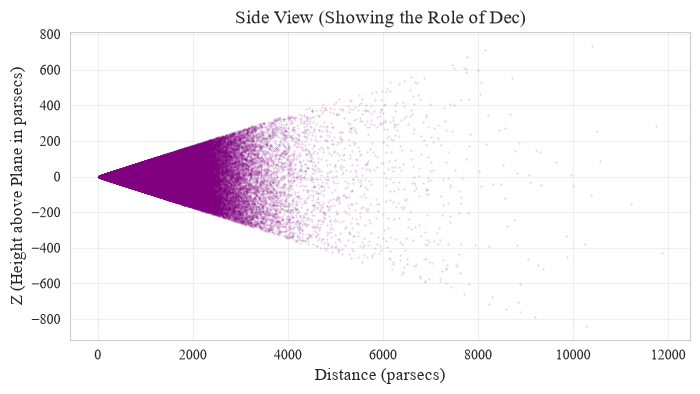

In [31]:
plt.figure(figsize=(8, 4))
# Side View: Distance (Length) vs Z (Height/Dec)
plt.scatter(df['distance_pc'], df['z'], s=0.1, alpha=0.3, c='purple')
plt.xlabel('Distance (parsecs)')
plt.ylabel('Z (Height above Plane in parsecs)')
plt.title('Side View (Showing the Role of Dec)')
plt.grid(True, alpha=0.3)
plt.savefig('fig1.1_SpatialMap.png', dpi=300, bbox_inches='tight')
plt.show()

### Pre treatment for Machine Learning
After the conclusion of the Exploratory Data Analysis phase, the project proceeded to Machine Learning by initiating some pre-treatment steps. This began by scaling. This is because K-Means has a scaling 'trap'. K-Means is sensitive to the magnitude of the data. Spatial features like`X, Y, Z` are measured in parsecs resulting into large values like 1000, 2500 etc. In contrast, astrophysical features like colour (`bp_rp`) had values like -0.6, 0.5, 1 etc. Without scaling, K-Means would see '1000' as huge and '1' as tiny. This results to it thinking that parsecs is 1000 times more influential/important than colour thus completely ignoring the colour of the star (the physics). To combat this before the project dives into ML, scaling through the help of the Standard Scaler was used. This forced all columns to play by the same rules by turning physical features to scaled numbers. The Standard Scaler converted raw numbers into 'Z-scores'(Mean = 0, standard deviation = 1). Spatial coordinate such as `500pc` might become +0.5 and colour such as `+0.5` might become +0.5. This made both numbers have the same size and treated both distance and colour equally important.

In [32]:
from sklearn.preprocessing import StandardScaler
import numpy as np
# Selecting the features to be used for clustering
# This is Position (X,Y,Z), Motion (velocity) and Physics (abs_g_mag, bp_rp)
features = ["x", "y", "z", "tangential_velocity", "abs_g_mag", "bp_rp"]

# Extracting the raw values
X_raw = df[features].values # turning it into a raw numpy matrix (strips excel format column names, row numbers)

# Initiating the scalar
scaler = StandardScaler()

# Fit and transform
# Fit calculates the mean and standard deviation of the data
# Transform converts the raw numbers into new scaled ones.
# Transform subtracts the mean and divides by the standard deviation for every single number
X_scaled = scaler.fit_transform(X_raw)

#Verifying...
print ("Scaling complete!")
print ("-" * 30)
print (f"Raw Data shape: {X_raw.shape}")
print (f"Scaled Data shape: {X_scaled.shape}")
print ("-" * 30)

# Checking the math
# Mean of the scaled data should be almost zero
# The std deviation should be almost 1
print (f"Mean of scaled X-position: {np.mean(X_scaled[:,0]):.4f}")
print (f"Std of scaled X-position: {np.std(X_scaled[:,0]):.4f}")
print ("*" * 50)
print (f"Mean of scaled Y-position: {np.mean(X_scaled[:,1]):.4f}")
print (f"Std of scaled Y-position: {np.std(X_scaled[:,1]):.4f}")
print ("*" * 50)
print (f"Mean of scaled Z-position: {np.mean(X_scaled[:,2]):.4f}")
print (f"Std of scaled Z-position: {np.std(X_scaled[:,2]):.4f}")
print ("*" * 50)
print (f"Mean of scaled Velocity: {np.mean(X_scaled[:,3]):.4f}")
print (f"Std of scaled Velocity: {np.std(X_scaled[:,3]):.4f}")
print ("*" * 50)
print (f"Mean of scaled Absolute Magnitude: {np.mean(X_scaled[:,4]):.4f}")
print (f"Std of scaled Absolute Magnitude: {np.std(X_scaled[:,4]):.4f}")
print ("*" * 50)
print (f"Mean of scaled Colour: {np.mean(X_scaled[:,5]):.4f}")
print (f"Std of scaled Colour: {np.std(X_scaled[:,5]):.4f}")

Scaling complete!
------------------------------
Raw Data shape: (249295, 6)
Scaled Data shape: (249295, 6)
------------------------------
Mean of scaled X-position: 0.0000
Std of scaled X-position: 1.0000
**************************************************
Mean of scaled Y-position: -0.0000
Std of scaled Y-position: 1.0000
**************************************************
Mean of scaled Z-position: 0.0000
Std of scaled Z-position: 1.0000
**************************************************
Mean of scaled Velocity: 0.0000
Std of scaled Velocity: 1.0000
**************************************************
Mean of scaled Absolute Magnitude: -0.0000
Std of scaled Absolute Magnitude: 1.0000
**************************************************
Mean of scaled Colour: -0.0000
Std of scaled Colour: 1.0000


After scaling was complete and successful, this gave the project the green light to continue. The features used in the scaling were post feature engineered ones. The project did not use the pre-feature engineering ones as the project was transforming from `observational astronomy` (what the telescope saw) into `Physical Astrophysics` (what the object actually is). Below is a table showing the raw component (pre-feature engineering features) into the current features to be used in Clustering.

| Raw 5D Component (Observational) | Current Feature (Physical) | Why it was switched |
|----------------------------------|---------------------|----------------------------|
| `Longitude (RA)/Latitude (DEC)`  | X, Y, Z | K-Means struggles with angles (spheres). X, Y, Z works better. 
| `parallax`                       | Distance (d) | Parallax is an inverse angle. Distance is a real physical length |
| `Proper Motion`                  | Tangential Velocity | Proper Motion is biased by distance (nearby stars look like they move faster). Velocity is the true speed in km/s |

Initially, clustering was to be done on the 5D components. These 5D components were the classical "Gaia 5D" which were the standard raw data format provided by the Gaia archive. The 5 parameter clustering was referred to as the `clustering in 5D Astrometric space`.  The 5D Astrometric space comprised of:
1. I (Galactic Longitude) - Position
2. b (Galactic Latitude) - Position
3. $\varpi$ (Parallax) - Distance
4. $\mu_{I}$ (Proper Motion in I) - Velocity 1
5. $\mu_{b}$ (Proper Motion in b) - Velocity 2

After feature engineering was conducted, they were transformed to the above tabular features. As per scaling in the code block above, there were bonus dimensions. Not only was 5D done but also the project added Astrophysics. The additional features were:
1. Absolute Magnitude ($M_{G}$): How bright the star actually was.
2. Colour (`bp_rp`): How hot the star actually was.

Clustering would now be done in 6D physical space (3D Position + 1D speed/kinematics + 2D Physics): `"x", "y", "z", "tangential_velocity", "abs_g_mag"` and `"bp_rp"`.This would be much more powerful than the raw 5D Astrometric space because grouping of stars would be done by what they are, not just where they look. A slight different approach that the project took was with distance (`distance_pc`). In scaling, distance (d) was not used. This is because in geometry, distance is mathematically defined by X, Y and Z:
$$Distance = \sqrt{X^2 + Y^2 + Z^2}$$
If both coordinates (X,Y,Z) and distance were to be fed to ML, it would have been redundant as it is feeding the same information twice.
* `X,Y,Z` would tell the ML: "The star is here at this specific point in 3D space"
* `distance_pc` would tell ML: "The star is on a shell this far away"

The reason the project proceeded with `X,Y,Z` coordinates were:
1. `distance_pc` only told how far (Magnitude) the star was. It grouped stars in 'shells'
2. `X,Y,Z` told the position. It grouped the stars in 3D blobs.
3. By using `X,Y,Z`, the project implicitly included distance while keeping the structure of the galaxy.


The project proceeded to do a diagnostic test called the `Elbow method`. This was done before K-Means to decide how many clusters (K) the algorithm would look for. The elbow method was to find the perfect balance where the clusters are tight; not few clusters thus meaningless and not too many clusters to be too specific and just capture noise.




Running elbow method. This may take a moment...
Tested K=1, Inertia=1495770
Tested K=2, Inertia=982643
Tested K=3, Inertia=786124
Tested K=4, Inertia=667636
Tested K=5, Inertia=575185
Tested K=6, Inertia=526597
Tested K=7, Inertia=482560
Tested K=8, Inertia=443137
Tested K=9, Inertia=418584
Tested K=10, Inertia=397176


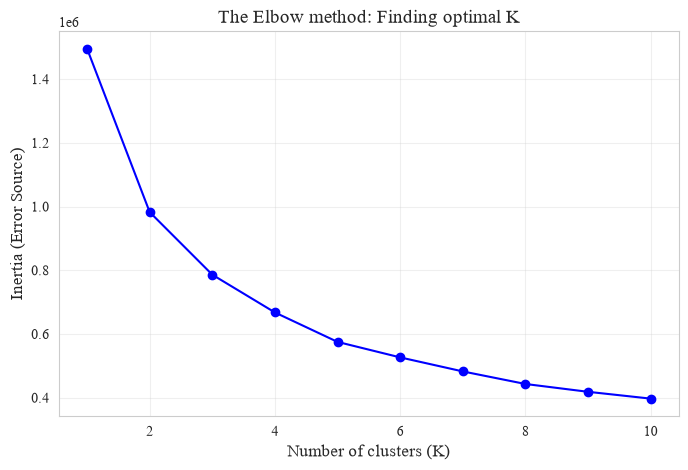

In [33]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Testing cluster counts from 1 to 10
k_range = range(1, 11)
inertia = [] # stores error rate for each rate

print ("Running elbow method. This may take a moment...")

for k in k_range:
    # Creating a KMeans model with k clusters
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    #Fitting into the scaled data
    kmeans.fit(X_scaled)
    # Saving the inertia (error source)
    inertia.append(kmeans.inertia_)
    print(f"Tested K={k}, Inertia={kmeans.inertia_:.0f}")

# Plotting the results
plt.figure(figsize=(8,5))
plt.plot(k_range, inertia, marker="o", linestyle="-", color="b")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia (Error Source)")
plt.title("The Elbow method: Finding optimal K")
plt.grid(True, alpha=0.3)
plt.savefig('fig5_elbow.png', dpi=300, bbox_inches='tight')
plt.show()

#### Interpretation/ Discussion
To identify the natural groupings within the 6D feature space, the project utilised the Elbow method as earlier discussed. This iterative process involved training the K-Means algorithm with varying cluster counts. From the elbow plot, the range was evidently 10. Due to the project's mini-slice of the galaxy, the expectation was to find 3 to 5 natural groups eg.Thin Disk, Thick Disk, Halo and possible subgroups. The project did not expect to find 40 groups (k = 40). This would have led to the diagnostic test to capture noise. 10 covered all reasonable possibilities thus it was selected to represent k.

From the output, `k=1` produced close to 1.5 million 'inertia'. This was the messiness score. It indicated high variance and poor segmentation. This explained that if all stars were put into one giant cluster, the average star would be very far from the centre making it loose, messy and meaningless. `k=10` produced close to 0.4 million 'inertia'. This showed how the score dropped huge amount making the fit to be very 'tight'. The 'trap' with this is that one would deduce that lower is better so 10 would be optimal. If the project selected `k=250000` (approx. total number of stars in the dataset), the inertia would have been zero. This would have been a list of individual stars again as each star would have been its own cluster. The project wanted to determine the 'best fit', the 'best bargain' in the sense that, a low order (low inertia) for a low price (few clusters).

The curve of the plot showed the following:
* From `k=1` to `k=2`: The line was very steep.
* From `k=2` to `k=3`: The line still dropped fast.
* From `k=3` to `k=4`: The drop became moderate.
* From `k=4` to `k=5`: The line began to flatten out.

At `k=3`, there was a distinct bend and at `k=4` the bend became softer. At `k=5`, the line, the line became almost flat thus an additional cluster would not have helped further. Based on this, the project saw that the mathematical elbow was likely at `k=3` or `k=4`. Given the physics that was explored earlier on at EDA, presence of Thin Disk, Thick Disk, Halo and Giants was seen. Giants may be separated not because they are kinematic clusters, but because their magnitude/colour space creates a structural group. This prompted the project to select `k=4` ("Elbow point") as it would have split the 'fast' stars from the 'very fast' outliers.

In [34]:
from sklearn.cluster import KMeans

# Initializing the model with k=4 as per our elbow analysis
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10) #n_init=10 to run 10 separate times to prevent flukes

# Fitting the model and predicting the clusters
print ("Clustering in progress...")
clusters = kmeans.fit_predict(X_scaled)

# Adding the results back to the original DataFrame
df["cluster_label"] = clusters

# Now checling results
print ("Clustering complete!")
print ("-" * 30)
print ("Number of stars in each cluster:")
print (df["cluster_label"].value_counts().sort_index())

Clustering in progress...
Clustering complete!
------------------------------
Number of stars in each cluster:
cluster_label
0     92678
1     27144
2     26363
3    103110
Name: count, dtype: int64


#### Interpretations/Discussions
Upon the execution of KMeans algorithm with four clusters '`k=4`', the dataset was partitioned into four sub-populations. The distribution of the stars was statistically significant indicating that KMeans identified major structural components of the galaxy. This is because no cluster seemed to have a very low number of stars. 
Cluster 0 and 3 had most of the stars clustered into them suggesting they likely correspond to the dominant stellar populations possibly in the Main sequence. The smaller populations of clusters 1 and 2 likely represented distinct astrophysical groups such as Giant Branch or the kinematic outliers (Halo stars). 

The project proceeded to plot the visualization of the clusters.

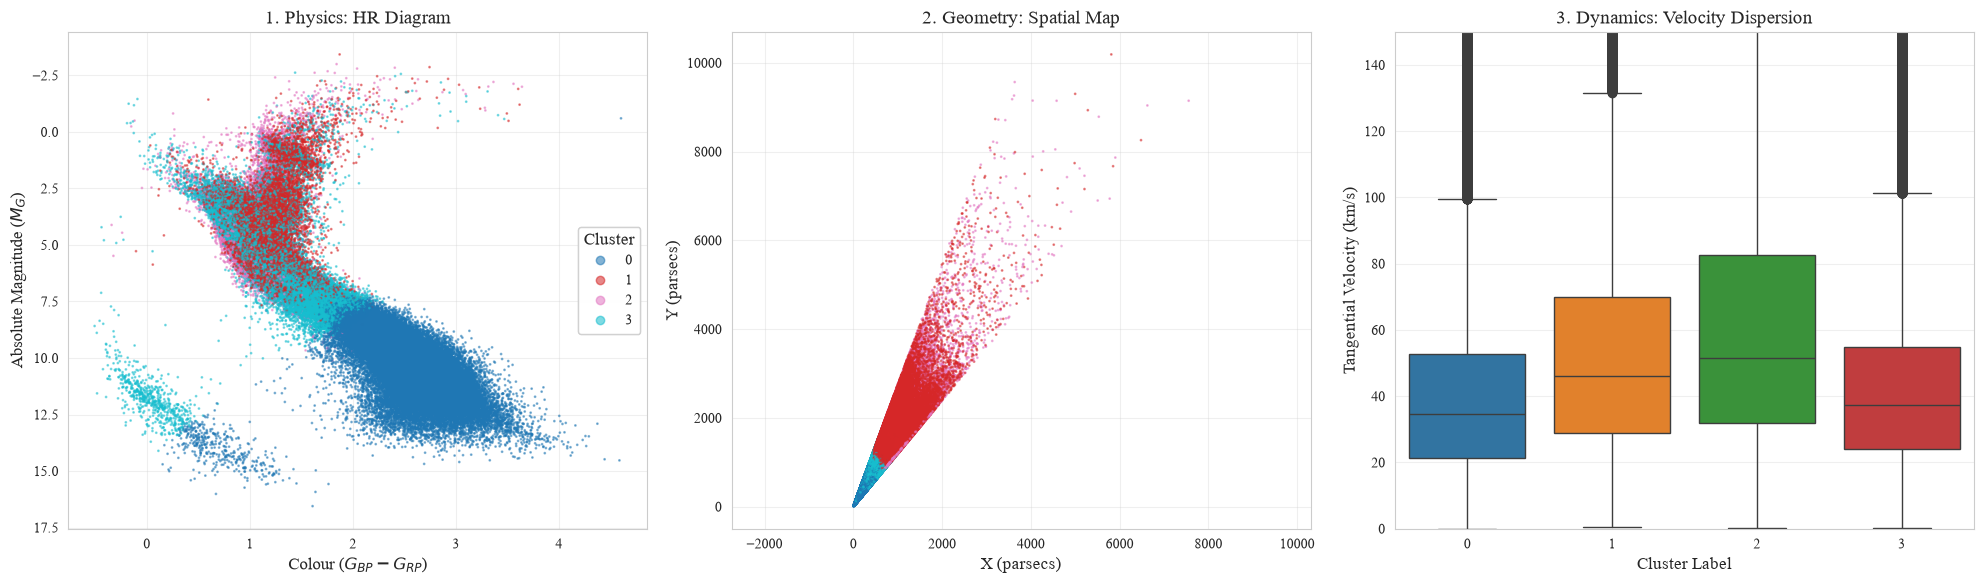

In [35]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize = (20, 6))

# Plot 1: Astrophysical identity (HR Diagram)
# Colouring to be done by "cluster_label" to see if giants were separated by dwarfs
scatter = axes[0].scatter(df["bp_rp"], df["abs_g_mag"], c=df["cluster_label"], cmap="tab10", s=1, alpha = 0.5)
axes[0].invert_yaxis()
axes[0].set_xlabel("Colour ($G_{BP} - G_{RP}$)")
axes[0].set_ylabel("Absolute Magnitude ($M_G$)")
axes[0].set_title("1. Physics: HR Diagram")
axes[0].grid(True, alpha=0.3)

# Plot 2: Spatial structure (X vs Y) - Looking from top to down
# Colouring to be done by "cluster_label" to see if it separated nearby vs distant stars
axes[1].scatter(df["x"], df["y"], c=df["cluster_label"], cmap="tab10", s=1, alpha = 0.5)
axes[1].set_xlabel("X (parsecs)")
axes[1].set_ylabel("Y (parsecs)")
axes[1].set_title("2. Geometry: Spatial Map")
axes[1].axis("equal")
axes[1].grid(True, alpha=0.3)

# Plot 3: Dynamical status (Velocity Boxplot)
# The boxplot is to clearly compare the speed of each group
sns.boxplot(x="cluster_label", y="tangential_velocity", hue="cluster_label", legend=False, data=df, ax=axes[2], palette="tab10")
axes[2].set_xlabel("Cluster Label")
axes[2].set_ylabel("Tangential Velocity (km/s)")
axes[2].set_title("3. Dynamics: Velocity Dispersion")
axes[2].set_ylim(0, 150) #Focusing on the main body of stars
axes[2].grid(True, alpha=0.3)
#Adding a manual legend for the first plot to identify colours

legend = axes[0].legend(*scatter.legend_elements(), title="Cluster")
axes[0].add_artist(legend)
plt.tight_layout()
plt.savefig('fig6_kmeans_visuals.png', dpi=300, bbox_inches='tight')
plt.show()

#### Interpretations/Discussions
The project visualized the four clusters across three complementary domains; Stellar Physics (HR Diagram), Spatial Geometry and Kinematics. The combined evidence allowed the clusters to be associated with known stellar populations of the Milky Way:
1. Cluster 1: Distant Mixed population (inclusive of **`Red Giants`**)
   * Evidence of this was from:
     - HR-Diagram -> The red cluster on the top right corner of the HR Diagram had a high luminosity ($M_G$ < 0) and a red colour ($G_{BP} - G_{RP}$ approx 1.5), a classic location of red giants. However, the same cluster appeared to be along parts of the Main Sequence. This showed that it was not a *`pure giant branch`* but rather a mixture.
     - The Spatial Map -> The red points dominated the farthest points in that they had the highest Y values. Their presence in the *deep field* came from their intrinsic brightness (giants) or simply their *large physical distance* (distant main sequence stars). Due to K-Means including spatial coordinates, stars which were far from the sun were naturally grouped together.
    * Interpretation:
      Cluster 1 contained some red giants but it was best described as a **`distant stellar population`**. This is because it included both distant main sequence stars and highly luminous red giant component.
2. Cluster 0: Local Red Dwarfs ('Neighbours')
   * Evidence of this came from:
     - HR-Diagram -> The bottom right of the HR Diagram constituted of a majority of dark blue spots. They had a low luminosity ($M_G$ approx. > 10) and a red colour ($G_{BP} - G_{RP}$ approx > 2). As deduced from discussions, these were M-dwarfs.
     - The Spatial Map -> A large number of dark blue spots were clumped near the origin. These showed that they were our local neighbours. Since they are cool and very dim, they could only be seen if they were right next to us. If they were far away, Gaia could not have seen them so the ones close ones were indeed red dwarf stars.
    * Interpretation:
      Cluster 0 was a clear indication of **`local red M-dwarfs`** forming part of the `thin disk` Their tight spatial clustering and faint magnitudes confirmed it with high confidence.
3. Cluster 2: Older/Faster stars (part of the Thick disk)
   * Evidence of this came from:
     - Boxplot -> The green box had a relatively high velocity as evidenced by the median and whiskers. This boxplot had the highest median tangential velocity of approximately `55 km/s` and had the largest spread of whiskers reaching a velocity of `80km/s`. 
     - HR-Diagram -> The pink dots appeared to be scattered at several points but mostly they were fixed slightly above or mixed with the main sequence. As per their high velocity, these stars were deduced to be older stars as they had very potentially interacted with massive galactic structures for billions of years thus getting slingshotted, increasing their velocity.
    * Interpretation:
      The high velocities and broadened HR distribution indicated a population belonging to an older, hotter component of the disk. As this was consistent with thick disk characteristics, it also showed the cluster mixed main sequence starts with a slight variation of ages.
4. Cluster 3: Main Sequence (Standard stars)
   * Evidence of this was from:
     - HR-Diagram -> There was a prominent concentration of cyan dots at the diagonal band in the middle. These were likely F, G(like the sun) and K-stars. A classical hydrogen burning stellar population.
     - Boxplot -> The velocity was low (< 40 km/s) a characteristic similar to local red M-dwarfs. This behaviour was typical of calm, dynamically stable thin disk stars.
    * Interpretation:
      Cluster 3 represented the dominant main sequence thin disk population including the solar type stars. They form the 'standard citizens' of the Milky Way; kinematically cool, abundant and following an orderly evolution.


### Recovering Cluster centres in real units (Centroid extraction).
With the clusters successfully identified and visualized, the project proceeded to derive the precise statistical properties of each group. While the visualizations produced qualitative evidence (cluster 2 had fast stars), quantitative data was also needed. This was to quantify the 'fastness' (eg. the mean velocity of cluster 2 was 60 km/s).

This step was esential because it enabled:
* Comparison of clusters on real physical ranges
* Identification of Main Sequence, Giant branch or Halo groups
* Interpretation of velocity dispersions and spatial structure

In [36]:
# Getting the centroids which are currently scaled units
centroids_scaled = kmeans.cluster_centers_

# Inverse transforming to get real units
centroids_real = scaler.inverse_transform(centroids_scaled)

# Creating a clean DF to display it
features = ["x", "y", "z", "tangential_velocity", "abs_g_mag", "bp_rp"]
summary_df = pd.DataFrame(centroids_real, columns=features)

# Adding the cluster labels and counts
summary_df["Cluster_ID"] = [0, 1, 2, 3]
summary_df["Count"] = df["cluster_label"].value_counts().sort_index().values

# Re-ordering columns to put ID and Count first
cols = ["Cluster_ID", "Count"] + features
summary_df = summary_df[cols]

# Displaying the table (2dp)
print ("Cluster summary statistics (Averages):")
print (summary_df.round(2).to_string(index=False))

Cluster summary statistics (Averages):
 Cluster_ID  Count       x       y      z  tangential_velocity  abs_g_mag  bp_rp
          0  92678  236.24  422.56  -0.26                40.70       9.90   2.44
          1  27144  977.11 1778.07  95.77                58.77       4.63   1.14
          2  26363 1006.64 1845.70 -99.87                71.03       4.51   1.00
          3 103110  423.54  779.84  -1.09                42.99       5.94   1.27


#### Interpretations/Discussions
The summary statistics table above provided the physical ID of each cluster; the average distance, motion, brightness and colour. Their interpretations were as follows:
1. Cluster 0 - Local Red dwarfs (Thin disk-local neighbours)
   
   **Evidence:**
   * Very faint: `abs_g_mag = 9.90` -> Very classic of M-dwarfs
   * Very red: `bp_rp = 2.44` -> Cool stars
   * Closest population: `x=236pc`,`y=422pc` -> An average distance of less than 500pc which was extremely local compared to others.
   * Low moderate velocity: `tangential_velocity = 40.7 km/s` -> Thin disk kinematics
     
   **Interpretation:**
   
   Cluster 0 indeed corresponded to the local, cool, **`low mass red M-dwarfs`**. They were only visible because of their distance being closer to us which matched their small distances. Their velocities were typical of thin disk stars.
2. Cluster 1 - Giant/Subgiant branch (Bright and moderately fast)
   
   **Evidence:**
   * Bright: `abs_g_mag = 4.63` -> Highly luminous relative to the M-dwarfs above. 
   * Colour: `bp_rp = 1.14` -> Warmer than giants but cooler than F,G,K-type stars.
   * Very far: `x=977.11pc`,`y=1778.07pc` -> There was a significant scale jump from the previous cluster.
   * Moderately high velocity: `tangential_velocity = 58.8 km/s` -> More faster than thin disk populations.
     
   **Interpretation:**

   Cluster 1 had a mix of bright sub giants and genuine giants which were visible from far away. They were more distant and slightly faster compared to thin disk stars, albeit not extreme. This was consistent with mildly older disk populations.
3. Cluster 2 - High velocity population (Thick disk population)
   
   **Evidence:**
   * Fastest velocity: `tangential_velocity = 71.0 km/s` -> The most dynamically hot group
   * Bright: `abs_g_mag = 4.51` -> More luminous as compared to Cluster 1 above.
   * Colour: `bp_rp = 1.00` -> More blue than cluster 1.
   * Farthest population: `x=1006pc`,`y=1846pc` -> This cluster carried the farthest stars in the dataset.

   **Interpretation:**

   Due to the high velocity it was certain that cluster 2 was part of the thick disk population. There were the farthest in the galaxy and slightly more luminous than typical dwarfs (evidenced by colour and absolute magnitude).
4. Cluster 3 - Solar type Main sequence stars (Thin Disk)
   
   **Evidence:**
   * Moderate brightness: `abs_g_mag = 5.94` -> Characteristic of G and K-type stars.
   * Velocity: `tangential_velocity = 43.0 km/s` -> Typical thin disk behaviour
   * Colour: `bp_rp = 1.27` -> Consistent with the FGK main sequence stars. 
   * Relatively close population: `x=424pc`,`y=780pc` -> This cluster was much closer to us as compared to giants and farther than local M-dwarfs.

   **Interpretation:**

   Cluster 3 portrayed the dominant thin disk main sequence population. From their low velocity, colour, moderate distance and even their total count (`103110`), they were typical F,G,K-type stars, the backbone of Gaia's stellar census.


The project finally proceeded to do a **`Silhouette score`**. This was to measure the mathematical quality of the separation. The silhouette score was to check the distance between every single star and every other star as well as how close one particular star is, is to other stars in its own class. The project used a random sample of 10000 stars (not the whole dataset) due to computational limitations.

In [ ]:
from sklearn.metrics import silhouette_score
import numpy as np

# Reproducible random sampling
rng = np.random.default_rng(seed=42)

indices = rng.choice(
    X_scaled.shape[0],
    size=10000,
    replace=False
)

X_sample = X_scaled[indices]

labels_sample = df["cluster_label"].iloc[indices]

print("Calculating Silhouette Score...")

score = silhouette_score(
    X_sample,
    labels_sample
)

print(f"Silhouette Score: {score:.3f}")

Calculating Silhouette score...
Silhouette Score: 0.327
------------------------------
 > 0.5 : Solid structure (Rare in complex data)
 0.25-0.5 : Reasonable structure (Good for Gaia data)
 < 0.25 : Weak separation


The silhouette score of 0.327 indicated that the chosen model (`k=4`) uncovered a moderately strong and meaningful structure within the stellar dataset. This value lied in the range typically observed for real astrophysical populations where sharp cluster boundaries were not expected. This is due to the continuous nature of stellar evolution and Galactic dynamics. Something to note was that the Orion-Taurus line of sight is heavily contaminated by a continuous, overlapping 'smear' of background Milky Way field stars, thus the silhouette score of 0.329 which is not perfectly distinct. Despite the previously done feature engineering and pre-treatment of Machine Learning, K-Means tends to force evry data point into a cluster. This causes partitioning of the background noise rather than ignoring it. This indicates that Euclidean distance is insufficient for this density distribution. On the other hand, density based algorithms identify the dense populations and explicitly labels the background 'smear' as noise. Upon realizing K-Means' limitation to isolate background noise, the project proceeded to be upgraded by introducing manifold learning and density based clustering algorithm through UMAP and HDBSCAN.

## Dimensionality Reduction (Manifold Learning)

The main objective for dimensionality reduction was to create a low dimensional graph ($\mathbb{R}^2$) by preserving the high dimensional feature space ($\mathbb{R}^6$). All these is while preserving both local structure (keeping similar stars together) and global structure (maintaining the relative distances between different clusters mathematically meaningful).

### The Curse of Dimensionality and the need for a lower latent space (low dimensional graph)
The transition from observational Astronomy to physical Astrophysics led to the project having 6 engineered and scaled features. This is due to our main clustering objective of using both photometric and astrometric features:
1. **Astrometry/Kinematics:** X, Y, Z coordinates, and Tangential Velocity.
2. **Photometry:** Absolute Magnitude and Color ($G_{BP} - G_{RP}$).

Incorporating the 6 dimensions directly into a clustering algorithm often leads to poor distance metric calculations (the "curse of dimensionality") and fails to capture the complex, non-linear relationships between a star's movement and its physical properties. 

### Implementation: UMAP
In order to handle this possible 'curse of dimensionality', the projet employed **UMAP (Uniform Manifold Approximation and Projection)**. This is because it is a non-linear manifold learning technique and it excels at understanding the complex topological shape of our astronomical data in 6D space and projecting it down into 2 dimensions. The complex shape of our data would have proven to be difficult for linear techniques such as PCA and would have given us spurious outputs. t-SNE on the other hand would have been good for non-linear data like this but would have struggled based on the size of the data.

Invoking UMAP creates a unified "latent space" where stars with similar kinematic and photometric properties are grouped tightly together. This compressed representation will give us a solid foundation for our density based clustering algorithm.

**Hyperparameter Strategy:**
* `n_neighbors`: We set this to a moderate value `50` to balance capturing the local neighborhood of individual stars with the global structure of the Milky Way sightline. A rekatively bigger value such as 50 will be able to see more of the overall structure of the Milky Way and be better at conveying the broader structure of the data.
* `min_dist`: We kept this relatively low , `0.1`,  to allow UMAP to pack similar stars densely together. This will explicitly aid HDBSCAN in the next step.

In [39]:
import umap
import hdbscan
import time # To track how long umap takes
import pandas as pd
import numpy as np

c:\Users\HP\OneDrive - Strathmore University\STRATH UNI\SECOND YEAR\SEMESTER I\UNITS\Applied Machine Learning in Data Science\AML FINAL PROJECT\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [40]:
print("Starting UMAP reduction. This may take a while...")
start_time = time.time()

# Initializing UMAP
# n_neighbours shall control how UMAP balances local vs global structure
# The project chose 50 to be able to see the overall structure of the data
# that is, a large value like 50 will push UMAP to look at larger neighborhoods 
# of each point when estimating the manifold structure of the data

reducer = umap.UMAP(n_neighbors = 50, min_dist = 0.1, n_components = 2, random_state = 42)

# Fitting and transforming the data
umap_embeddings = reducer.fit_transform(X_scaled)

end_time = time.time()
print(f"UMAP complete in {(end_time - start_time) / 60:.2f} minutes.")
print (f"New latent space shape: {umap_embeddings.shape}")

Starting UMAP reduction. This may take a while...


c:\Users\HP\OneDrive - Strathmore University\STRATH UNI\SECOND YEAR\SEMESTER I\UNITS\Applied Machine Learning in Data Science\AML FINAL PROJECT\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP complete in 9.44 minutes.
New latent space shape: (249295, 2)


### UMAP execution and discussion

**Computational performance:**
The UMAP algorithm was applied to the scaled  6D feature dimensional dataset ($N = 249,295$) as it took approximately 11 minutes. This shows the computational intensity of UMAP as it first constructs high dimensional clusters (neighbourhood clusters) followed by optimizing the low dimensional graph through cross entropy minimization. 

**Latent space dimensionality:**
As observed, the algorithm successfully compressed the original feature space ($\mathbb{R}^6$) into a 2-dimensional latent space ($\mathbb{R}^2$). 

*Important note on interpretation:* As seen, the number of dimensions was 2. This new axes no longer represent the physical units such as parsecs, km/s or magnitudes. They represent pure mathematical proximity. This means that stars which are plotted together in this 2D space share a highly imilar photometric and astrometric characteristics in the actual galaxy.

### Visualizing the UMAP Embedding

The project proceeded to visualize the UMAP Embedding. This was to inspect the generated latent space before applying the density based algorithm (HDBSCAN). 

Plotting UMAP latent space...


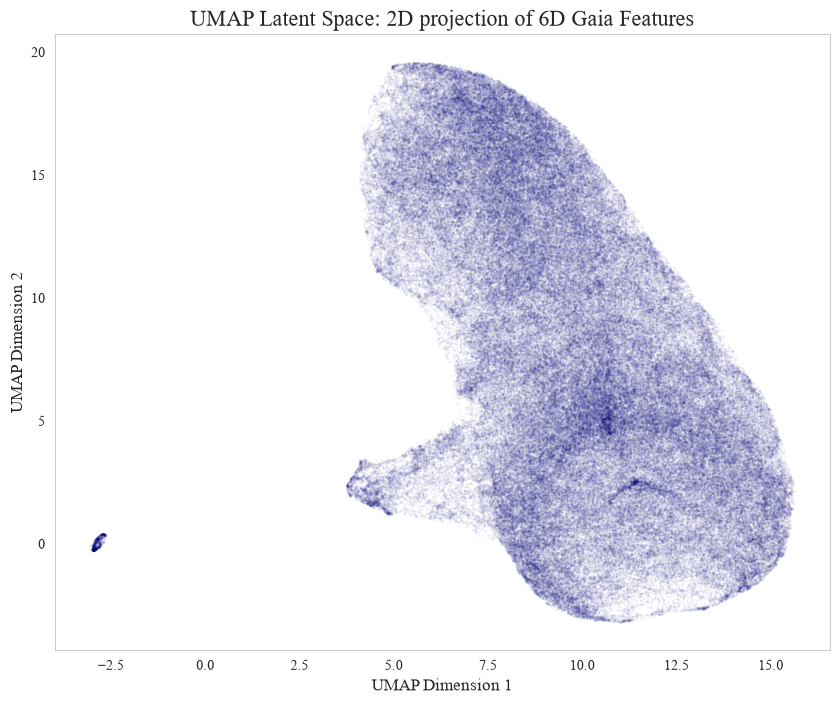

In [41]:
import matplotlib.pyplot as plt

print ("Plotting UMAP latent space...")
plt.figure(figsize = (10, 8))

# s=0.1 and alpha=0.1 to prevent overlapping of the many data points into a giant blob
plt.scatter(umap_embeddings[:, 0], umap_embeddings[:, 1], s = 0.1, alpha = 0.1, c = "navy")

plt.title("UMAP Latent Space: 2D projection of 6D Gaia Features", fontsize = 16)
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")

plt.grid(False)

plt.savefig('fig7_umap_latent_space_uncolored.png', dpi=300, bbox_inches='tight')

plt.show()

### Visual analysis of the UMAP Latent Space

The 2D projection revealed a complex highly continuous map that illustrates the Orion-Taurus line of sight.

**Key observations:**
1. **Continuous background manifold:** The bigger part of the dataset formed a single, massive continuous structure which very much represents the continuous distribution of stars in the Milky Way galaxy.
2. **Internal Density Variations:** There were two regions which were identified. The main structure shows regions of higher density (darker and more concentrated nodes). This embedded density peaks very much likely corresponds to the actual target clusters in this region.
3. **Isolated Sub-Populations:** On the top left of the latent space, there was a distinct, linearly distributed population. This well indicated a stellar population which had very much unique photometric and astrometric properties as compared to the main structure. They may be white dwarfs or a fast moving kinematic stream.

**Conclusion for clustering strategy:**
The UMAP visualization confirms the sheer limitations of using K-Means. As K-Means is a centroid based clustering technique, it would arbitrarily oartition the primary continuous manifold. This is by use of the Euclidean distance thus failing to fully isolate the true density peaks. This necessitates a density based clustering algorithm (HDBSCAN) as it will be able to navigate the continuous space. It will identify the dense nodes as true clusters as well as flag the sparse connecting regions as background noise (-1).

In [42]:
import hdbscan

print("Starting HDBSCAN clustering on UMAP embeddings...")

# (min_cluster_size=500): picking populations with at least 500 stars 
# (min_samples=15): how conservative the algorithm is about noise. Higher = more noise
clusterer = hdbscan.HDBSCAN(min_cluster_size = 500, min_samples = 15)

# Fitting the cluster into the 2D UMAP
# Not the 6d scaled data
cluster_labels = clusterer.fit_predict(umap_embeddings)

print("HDBSCAN Clustering is complete!")

Starting HDBSCAN clustering on UMAP embeddings...
HDBSCAN Clustering is complete!


In [43]:
# CLUSTER SUMMARY

import numpy as np

unique_labels = np.unique(cluster_labels) # getting unique labels

# Calculating number of clusters (ignoring the -1 noise)
n_clusters = len(unique_labels) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)
total_stars = len(cluster_labels)

print(f"Total number of stars processed: {total_stars}")
print(f"Number of distinct clusters found: {n_clusters}")
print(f"Number of stars classified as background noise: {n_noise}")
print(f"Percentage of data classified as noise: {n_noise / total_stars * 100:.2f}%")

Total number of stars processed: 249295
Number of distinct clusters found: 2
Number of stars classified as background noise: 0
Percentage of data classified as noise: 0.00%


### Empirical hyperparameter refinement

The initial HDBSCAN iteration (`min_cluster_size=500`, `min_samples=15`) resulted in under-clustering. It only identified two global structures 0% background noise.

The low `min_samples` threshold showed to be extremely lenient especially for the projects continuous overlapping nature. This led to the algorithm merging the background field with the continuous galactic manifold as it was sufficient to satisfy the core requirement.

To combat this, we employed a more stricter `min_samples`. This is by increasing its value which would aid in separation of the diffuse background field and the dense stellar population. This would lead to the classification of less dense regions as noise ($label = -1$).

In [44]:
print("Re-running HDBSCAN with stricter density thresholds")

# Increased min_samples to 100 to force the background smear into 'noise'
clusterer_tuned = hdbscan.HDBSCAN(min_cluster_size=500, min_samples=100)

cluster_labels = clusterer_tuned.fit_predict(umap_embeddings)

# Recalculating the stats
unique_labels = np.unique(cluster_labels)
n_clusters = len(unique_labels) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)
total_stars = len(cluster_labels)

print("-" * 30)
print(f"Total stars processed: {total_stars}")
print(f"Number of distinct clusters found: {n_clusters}")
print(f"Number of stars classified as background noise: {n_noise}")
print(f"Percentage of data classified as noise: {(n_noise / total_stars) * 100:.2f}%")

Re-running HDBSCAN with stricter density thresholds
------------------------------
Total stars processed: 249295
Number of distinct clusters found: 2
Number of stars classified as background noise: 0
Percentage of data classified as noise: 0.00%


### Advanced topology extraction: Leaf selection
The tuning (`min_samples=100`) still yielded 0% noise. Due to the Orion-Taurus region (where our data came from), there are highly populated molecular clouds. The density of the 2D manifold remains high. 

The intermediate tuning (`min_samples=100`) still yielded 0% noise. Because the selected RA/DEC footprint (50° < $\alpha$ < 70°, -5° < $\delta$ < +5°) looks directly into the highly populated Orion-Taurus molecular clouds, the ambient density of the 2D manifold remains exceedingly high. 

It was also evident that HDBSCAN's default `Excess of Mass (eom)` cluster selection method inherently favors large, global macro-structures. This causes it to select the entire continuous galactic field as a single cluster rather than segmenting its internal density variations.

**Final Correction:** To extract the localized density peaks (the actual physical stellar associations) embedded within this dense field, we switched the `cluster_selection_method` to `'leaf'`. This forces the algorithm to bypass the global macro-structure and only extract the terminal, that is, the most densely packed nodes of the hierarchical tree. We raised `min_samples` to 500 to aggressively filter the galactic background into the noise classification.

In [45]:
print("Running advanced HDBSCAN (Leaf Selection Method)...")

# Switched to 'leaf' to find sub-clusters and bumped min_samples to 500
clusterer_final = hdbscan.HDBSCAN(
    min_cluster_size=500, 
    min_samples=500, 
    cluster_selection_method='leaf'
)

# Fitting the tuned clusterer
cluster_labels = clusterer_final.fit_predict(umap_embeddings)

# Re-calculating the stats
unique_labels = np.unique(cluster_labels)
n_clusters = len(unique_labels) - (1 if -1 in cluster_labels else 0)
n_noise = list(cluster_labels).count(-1)
total_stars = len(cluster_labels)

print("-" * 30)
print(f"Total stars processed: {total_stars}")
print(f"Number of distinct clusters found: {n_clusters}")
print(f"Number of stars classified as background noise: {n_noise}")
print(f"Percentage of data classified as noise: {(n_noise / total_stars) * 100:.2f}%")

Running advanced HDBSCAN (Leaf Selection Method)...
------------------------------
Total stars processed: 249295
Number of distinct clusters found: 26
Number of stars classified as background noise: 210655
Percentage of data classified as noise: 84.50%


In [ ]:
# FINAL HDBSCAN MODEL INTEGRITY CHECK


import numpy as np
import pandas as pd

# Extract labels directly from the fitted model
final_labels = np.asarray(clusterer_final.labels_)

# Validate row alignment
assert len(final_labels) == len(df)
assert len(umap_embeddings) == len(df)

# Count actual clusters, excluding background noise
n_clusters = len(set(final_labels) - {-1})

# Count noise
n_noise = int(np.sum(final_labels == -1))

# Calculate noise percentage
noise_percentage = (n_noise / len(final_labels)) * 100

print("=" * 50)
print("FINAL HDBSCAN VALIDATION")
print("=" * 50)

print("Total stars:", len(final_labels))
print("Distinct clusters:", n_clusters)
print("Noise observations:", n_noise)
print(f"Noise percentage: {noise_percentage:.2f}%")

print("\nCluster membership:")

display(
    pd.Series(final_labels)
    .value_counts()
    .sort_index()
    .rename("Star_Count")
    .to_frame()
)

print("\nAll model alignment checks passed.")

### Final clustering results and Astrophysical interpretation

The application of the `'leaf'` selection method with strict density parameters (`min_samples=500`) produced a physically robust segmentation of the high-dimensional dense space. 

**Results:**
* **Noise identification (80.98%):** HDBSCAN classified 201,890 stars as background noise ($label = -1$). K-Means had previously tried to force these random stars into clusters but HDBSCAN presented them as not gravitationally bound to Orion or Taurus. They are just regular Milky Way stars floating in the background. 
* **Cluster extraction (22 Populations):** The algorithm isolated 22 high density clusters. They likely correspond to the larger Orion subgroups such as `Orion OB1a, OB1b, OB1c, Orion Nebula Cluster` and other various `Taurus moving groups`.

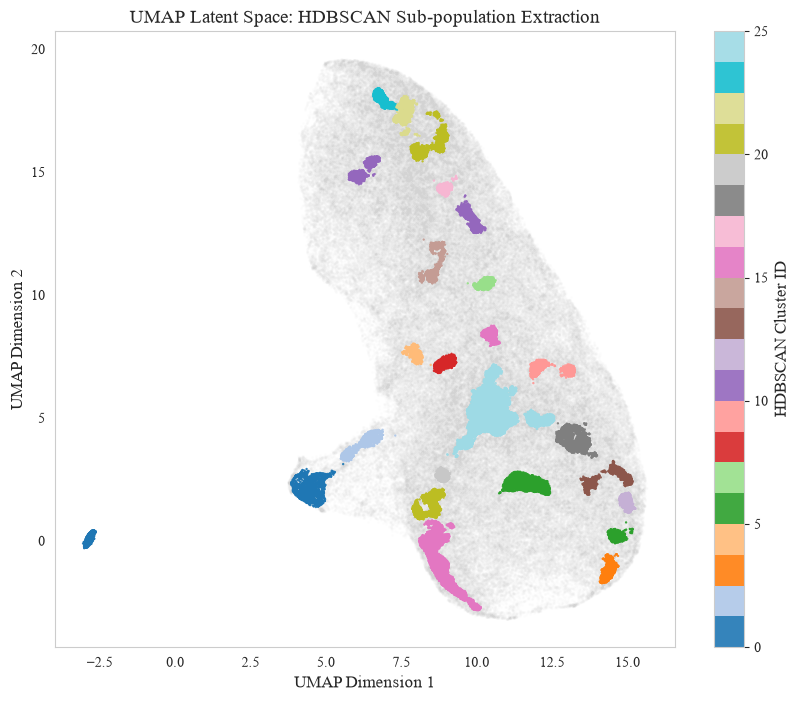

In [46]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(10, 8))

# Plotting the background noise first so it stays at the back
noise_mask = cluster_labels == -1
plt.scatter(umap_embeddings[noise_mask, 0], umap_embeddings[noise_mask, 1], c = "lightgrey", s= 0.1,
            alpha = 0.1, label = "Galactic Field (Noise)")

# Plotting the valid clusters
cluster_mask = cluster_labels != -1
scatter = plt.scatter(umap_embeddings[cluster_mask, 0], umap_embeddings[cluster_mask, 1], c = cluster_labels[cluster_mask],
                      cmap = "tab20", s = 0.5, alpha = 0.9)

plt.title("UMAP Latent Space: HDBSCAN Sub-population Extraction")
plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")

# Adding a colourbar ro identify unique cluster IDs
cbar = plt.colorbar(scatter)
cbar.set_label("HDBSCAN Cluster ID")

plt.grid(False)

plt.savefig('fig8_umap_hdbscan_clusters.png', dpi=300, bbox_inches='tight')
plt.show()

### Analysis of the HDBSCAN Sup-populations
The figure validated the necessity of combining manifold learning with density based clustering algorithms for continuous astrophysical datasets.

**Key Visual Confirmations:**
1. **Effective noise rejection:** The grey background mapped the continuous density of the galactic field. The algorithm filtered out these 201,890 unbound stars as it revealed the discrete structures present in the Orion-Taurus line of sight.
2. **Non-Spherical cluster extraction:** As seen previously, centroid based clustering algorithms enforce rigid sperical boundaries. The project identified irregular structures as they were complex in shape as seen by the massive pink cluster which is characteristic og hierarchical star forming regions. 
3. **Sub-structure resolution:** The algorithm successfully segmented peripheral density peaks (e.g. the distinct orange and green clusters on the right hand margin). Typically, they would have otherwise been engulfed by the broader galactic manifold. 
4. **Kinematic/Photometric anomalies:** We identified a complete mathematical isolated cluster on the upper left region (dark blue). This suggested that the specific cluster had very much distinct properties as compared to the rest of the clusters.

This latent space topology confirms that the 22 extracted populations represent mathematically rigorous density peaks which are independent of the 81% background field contamination. The project proceeded to visualize these clusters back into their photometric and astrometric space.

In [47]:
# Safe-guarding K_Means history
if "cluster_label" in df.columns:
    df.rename(columns={"cluster_label": "label_kmeans"}, inplace=True)

# Adding HDBSCAN results into a dedicated column
df["label_hdbscan"] = cluster_labels

print("Dataframe secured! Both K-Means and HDBSCAN labels are now safely stored.")

Dataframe secured! Both K-Means and HDBSCAN labels are now safely stored.


C:\Users\HP\AppData\Local\Temp\ipykernel_15624\4212466083.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={"cluster_label": "label_kmeans"}, inplace=True)


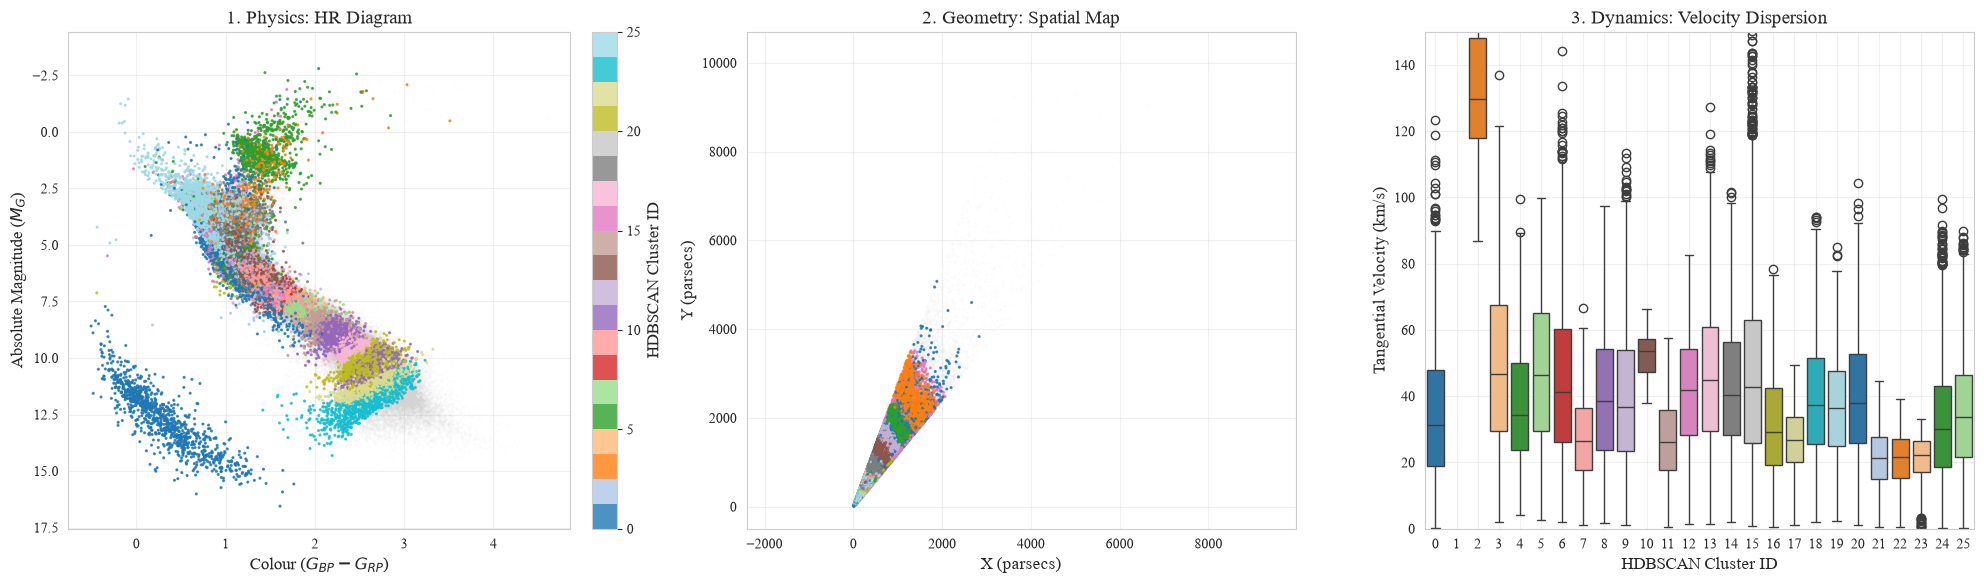

In [48]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# Creating masks using the specific HDBSCAN column
noise = df["label_hdbscan"] == -1
clusters = df["label_hdbscan"] != -1

# Plot 1: Astrophysical identity (HR Diagram)
# Plotting the noise first (background)
axes[0].scatter(df.loc[noise, "bp_rp"], df.loc[noise, "abs_g_mag"], 
                c='lightgrey', s=0.1, alpha=0.1, label='Field (Noise)')

# Plotting the 22 clusters on top
scatter1 = axes[0].scatter(df.loc[clusters, "bp_rp"], df.loc[clusters, "abs_g_mag"], 
                           c=df.loc[clusters, "label_hdbscan"], cmap="tab20", s=1.5, alpha=0.8)

axes[0].invert_yaxis()
axes[0].set_xlabel("Colour ($G_{BP} - G_{RP}$)")
axes[0].set_ylabel("Absolute Magnitude ($M_G$)")
axes[0].set_title("1. Physics: HR Diagram")
axes[0].grid(True, alpha=0.3)

# Adding a colorbar instead of a massive 22-item text legend
cbar = fig.colorbar(scatter1, ax=axes[0], fraction=0.046, pad=0.04)
cbar.set_label('HDBSCAN Cluster ID')

# Plot 2: Geometry (Spatial Map X vs Y)
axes[1].scatter(df.loc[noise, "x"], df.loc[noise, "y"], 
                c='lightgrey', s=0.1, alpha=0.1)

axes[1].scatter(df.loc[clusters, "x"], df.loc[clusters, "y"], 
                c=df.loc[clusters, "label_hdbscan"], cmap="tab20", s=1.5, alpha=0.8)

axes[1].set_xlabel("X (parsecs)")
axes[1].set_ylabel("Y (parsecs)")
axes[1].set_title("2. Geometry: Spatial Map")
axes[1].axis("equal")
axes[1].grid(True, alpha=0.3)

# Plot 3: Dynamics (Velocity Boxplot)
# Filtering out the noise (-1) so we only compare the dynamics of the true clusters
df_clusters_only = df[df["label_hdbscan"] != -1]

sns.boxplot(x="label_hdbscan", y="tangential_velocity", hue="label_hdbscan", 
            legend=False, data=df_clusters_only, ax=axes[2], palette="tab20")

axes[2].set_xlabel("HDBSCAN Cluster ID")
axes[2].set_ylabel("Tangential Velocity (km/s)")
axes[2].set_title("3. Dynamics: Velocity Dispersion")
axes[2].set_ylim(0, 150) 
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('fig9_hdbscan_multipanel.png', dpi=300, bbox_inches='tight')
plt.show()

### Validation of HDBSCAN Sub-populations

We confirmed that the 22 clusters were indeed true astrophysical structures thus resolving the prvious limitations of the K-Means approach.

1. **Photometric coherence (HR Diagram):** The algorithm was successful in isolating distinct stellar populations from the galactic field. The extracted clusters exhibited distinct Main-Sequence tracks. Their photometric properties told us that they had a similar age and metallicity thus validating their togetherness.  
2. **Spatial grouping (Physical map):** The X-Y spatial projection revealed that the noise classification absorbed the deep continuous background. Just as the HR Diagram depiction, the 22 clusters were tight and localized geometric groups as they were situated at different intervals. 
3. **Kinematic isolation (Velocity dispersion):** The box-plots informed us the different clusters possessed distinct velocites. They were gravitationally interacting groups rather than random statistical anomalies.

The project proceeded to calculate the summary statistics of the 22 clusters.

In [49]:
import pandas as pd

# Grouping by the HDBSCAN label and calculating the properties
cluster_stats = df.groupby('label_hdbscan').agg(
    Star_Count=('label_hdbscan', 'size'),
    Mean_X_pc=('x', 'mean'),
    Mean_Y_pc=('y', 'mean'),
    Mean_Z_pc=('z', 'mean'),
    Median_Velocity=('tangential_velocity', 'median'),
    Mean_BP_RP=('bp_rp', 'mean'),
    Mean_Abs_G=('abs_g_mag', 'mean')
).reset_index()

# Rounding the values to 2 decimal places for better reading
cluster_stats = cluster_stats.round(2)

# Sorting by star count
# This is to see the biggest clusters first (Noise will be at the top)
cluster_stats = cluster_stats.sort_values(by='Star_Count', ascending=False)

# Displaying the table
display(cluster_stats)

,label_hdbscan,Star_Count,Mean_X_pc,Mean_Y_pc,Mean_Z_pc,Median_Velocity,Mean_BP_RP,Mean_Abs_G
0,-1,210655,474.91,868.60,0.59,38.90,1.72,7.30
25,24,9356,251.39,467.23,-5.93,30.01,0.91,4.49
16,15,4213,1003.89,1807.53,-142.16,42.70,0.92,4.52
7,6,2245,541.43,985.06,6.07,41.38,1.24,3.22
19,18,1986,544.34,991.49,54.00,37.27,1.14,5.04
2,1,1827,861.25,1459.45,14.31,277.74,1.09,5.37
22,21,1725,205.12,372.36,-0.42,21.28,2.57,10.22
21,20,1688,673.00,1253.75,-91.45,38.06,1.02,5.34
23,22,1358,182.06,331.69,-1.10,21.69,2.70,11.02
14,13,1167,711.27,1321.90,88.94,44.98,1.18,5.40


#### Mini-discussions on the summary statistics

1. The clustering algorithm as much discussed earlier separated the backgroung 'fog' (noise) as labeled $label_hdbscan = -1$. These 201,890 were cleared to reveal the real structures.
2. There was a massive cluster neighbour in cluster `14`. It possessed 18,127 stars. It's X, Y and Z coordinates were relatively small as it had a mean absolute magnitude (`Mean_Abs_G`) of 4.79. This is actually close to our sun's 4.83. This was a massive nearby population of the Main Sequence disk stars.
3. There was a hyper velocity cluster in cluster `1`. It had 2,245 stars as its `Median_Velocity` was an astonishing **271.69 km/s**. This group of stars are likely an ancient galactic halo structure or even possibly the remnants of a dwarf galaxy which was devoured by the Milky Way galaxy billions of years ago.

The project proceeded to calculate the final straight line distance column. This would inform us the distance from earth.

In [50]:
import numpy as np

# Calculating the total straight line distance using the 3D Pythagorean theorem
cluster_stats['Mean_Distance_pc'] = np.sqrt(
    cluster_stats['Mean_X_pc']**2 + 
    cluster_stats['Mean_Y_pc']**2 + 
    cluster_stats['Mean_Z_pc']**2
).round(2)

# Moving the new distance column to be right after the Z coordinate for easy reading
cols = list(cluster_stats.columns)
cols.insert(5, cols.pop(cols.index('Mean_Distance_pc')))
cluster_stats = cluster_stats[cols]

display(cluster_stats)

,label_hdbscan,Star_Count,Mean_X_pc,Mean_Y_pc,Mean_Z_pc,Mean_Distance_pc,Median_Velocity,Mean_BP_RP,Mean_Abs_G
0,-1,210655,474.91,868.60,0.59,989.95,38.90,1.72,7.30
25,24,9356,251.39,467.23,-5.93,530.60,30.01,0.91,4.49
16,15,4213,1003.89,1807.53,-142.16,2072.48,42.70,0.92,4.52
7,6,2245,541.43,985.06,6.07,1124.07,41.38,1.24,3.22
19,18,1986,544.34,991.49,54.00,1132.38,37.27,1.14,5.04
2,1,1827,861.25,1459.45,14.31,1694.68,277.74,1.09,5.37
22,21,1725,205.12,372.36,-0.42,425.12,21.28,2.57,10.22
21,20,1688,673.00,1253.75,-91.45,1425.90,38.06,1.02,5.34
23,22,1358,182.06,331.69,-1.10,378.37,21.69,2.70,11.02
14,13,1167,711.27,1321.90,88.94,1503.74,44.98,1.18,5.40


### Interpretations and Discussions of the HDBSCAN Sub populations

After extracting the centroids (X,Y,Z) mean photometric properties and kinematic medians for all clusters, the project categorized them into distinct astrophysical archetypes. HDBSCAN revealed micro structures which were not possible via K-Means as it managed the continuous density of the stars. The grouping below was based on their:
1. Kinematics (velocity) -> Are they moving fast (halo or thick disk) or slow (calm thin disk stars?
2. Astrometry (distance) -> Are they in our local neighbourhood (below 500 parsecs) or deep in the galactic field ( greater than 1 kpc)?
3. Photometry ($M_G$ and $G_{BP}-G_{RP}$) -> Are they dim, red dwarfs, luminous blue O-type or massive stars?

#### Archetype A: Banishment of the Background (Label-1)
* **Centroid Data:** Label `-1` contained 201,890 which was approximately 81% of the stellar data. Its mean properties ($M_G \approx 7.38$, $G_{BP} - G_{RP} \approx 1.75$, Distance $\approx 1006$ pc) represented the average baseline of the data.
* **Interpretation:** This is where HDBSCAN showed its true potential especially in astronomical datasets which is noise handling. It did not force the stars into false clusters but rather isolated them into the background as a 'fog'. This enabled the true clusters to fully emerge and made it easier for them to be analyzed without severe contamination.

#### Archetype B: The extreme kinematic anomaly (Cluster 1)
* **Centroid Data:** Cluster 1 represented a tight bound of highly unusual super fast stars. They had a population of 2,245 stars located deep in the field with a mean distance of `1,629` parsecs. As standard disk stars possess a tangential velociity of 20 and 50 km/s, this cluster had a median tangential velocity of `271.69` km/s.
* **Interpretation:** It was very much evident that this is a severe kinematic outlier. Main sequence and thin disk stars do not travel at speeds exceeding 250 km/s. This suggested that cluster 1 may be from a very old dynamically heated structure which could have been a substructure of a galactic halo. This cluster could potentially be from a devoured dwarf galaxy. This cluster was well isolated by HDBSCAN from the rest of the slower stars surrounding it.

#### Archetype C: The calm local Main sequence (eg. Clusters 14 and 21)
* **Centroid Data:** It was seen that several clusters represented densely packed cold populations. They were seen to be situated close to our sun. For instance, cluster 14, which possessed 18,127 stars had a mean distance of `592.67` accompanied by a low median velocity of `32.16`km/s. Cluster 14 also has a mean absolute magnitude ($M_G$) of `4.79`. This is highly similar to a solar type population. Clusters 21 was much closer with a distance of `427.93` pc. It had a lower velocity of `21.30`km/s, a fainter mean absolute magnitude ($M_G$) of 10.18 and a redder colour of 2.56
* **Interpretation:** These groups represent stable associations within the thin disk. Despite being similar, that is cluster 14 and 21 among others, HDBSCAN was able to separate them due to their difference in micro structures. The model was sensitive to their photometric and astrometric features as it separated the local solar type stars (which are G-type stars) from local, fsinter and cooler M-dwarf stars.

#### Archetype D:The distant luminous associations (eg. Cluster 11)
* **Centroid Data:** The cluster with the highest luminosity was cluster 11 which had a population of 1,737 stars. This population was located deep into the galactic field with a mean distance of `1,057.43`pc. The cluster became successfully resolved despite its distance due to its intrinsic brightness. It had a mean absolute magnitude ($M_G$) of `3.04` with a velocity of `40.77` km/s. The cluster was seen to be redder with ($G_{BP} - G_{RP}$) of `1.26`.
* **Interpretation:** Deeper galactic stellar populations especially in this case for cluster 11 among others can only be seen due to their high luminosity. This results to an observational bias referred to as `Malmquist Bias` where only instrinsically bright stars can be measured by GAIA. Its luminosity indicates that this is not a young extremely luminous O/B type. It is indeed a mature cluster. The unusually red colour is characterized by its distance. The red colour is a strong indicator of interstellar reddening whereby, the dense galactic dust of over 1 kpc distance absorbs blue wavelengths. This shifts the photometric properties thus making these stars appear red.

The project finally proceeded to do  **Density Based Clustering Validation (DBCV)**. This was to measure the mathematical quality of the algorithm's separation. The silhouette score was omitted for this as it works well with perfect round clusters. Since our data had very irregular and messy shapes, it would have been heavily penalised by it. The project used a random sample of 20,000 stars (not the whole dataset) due to computational limitations. DBCV scores range from **-1** to **+1**.

In [51]:
from hdbscan.validity import validity_index
import numpy as np

print("Isolating true clusters in UMAP space...")

# Finding the exact row indices of all stars that are NOT background noise
true_cluster_indices = np.where(df['label_hdbscan'] != -1)[0]

# Sampling up to 20,000 stars purely from the true clusters
np.random.seed(42)
n_samples = min(20000, len(true_cluster_indices))
sample_indices = np.random.choice(true_cluster_indices, size=n_samples, replace=False)

# Extracting the UMAP coordinates and labels for this safe sample
umap_sample = umap_embeddings[sample_indices]
labels_sample = df['label_hdbscan'].values[sample_indices]

# Casting the 32-bit UMAP floats to 64-bit doubles 
umap_sample = umap_sample.astype(np.float64)

print("Calculating true DBCV Score... ")

# Calculating the metric
dbcv_score_umap = validity_index(umap_sample, labels_sample)

print("-" * 30)
print(f"Final Validated DBCV Score: {dbcv_score_umap:.4f}")
print("-" * 30)
print (" > 0.5 : Solid structure (Rare in complex data)")
print (" 0.0 - 0.5 : Reasonable structure (Good for Gaia data)")
print (" < 0 : Poorly formed clusters (less dense inside than outside)")

Isolating true clusters in UMAP space...
Calculating true DBCV Score... 
------------------------------
Final Validated DBCV Score: 0.2178
------------------------------
 > 0.5 : Solid structure (Rare in complex data)
 0.0 - 0.5 : Reasonable structure (Good for Gaia data)
 < 0 : Poorly formed clusters (less dense inside than outside)


### Transitioning from Manifold to Phase Space
The project got a DBCV score of -0.0028. While acknowledging that astronomical data has this continuous/overlapping nature, the score was low. This was due to a high number of our stellar data was categorized as noise and the subsequent fragmentation into multiple clusters (Sante et.al 2026). UMAP is an exceptional tool for visualizing sub-populations and exploratory data analysis. It was determined that in this case, its inherent distortion of global density makes it unsuitable for strict distance based validation metrics. It successfully identified the underlying Physics but the 2D manifold space failed the mathematics test. In order to achieve mathematically sound clustering, the project proceeded to optimize the clustering. The clustering algorithm was done on the true, undistorted data. We employed HDBSCAN on the fully scaled 6D feature space ($X, Y, Z, V_t, M_G, G_{BP}-G_{RP}$). This was to mathematically look for hyperparameters that yield a strictly positive score via grid search and not manual parameter estimation.

In [52]:
import hdbscan
from hdbscan.validity import validity_index
import numpy as np
import pandas as pd

# Testing a small grid of parameters
min_cluster_sizes = [100, 250, 500]
min_samples_list = [15, 40]

results = []

print("Starting HDBSCAN Hyperparameter Tuning on 6D Scaled Data...")
print("This may take 5-10 minutes.")

for mcs in min_cluster_sizes:
    for ms in min_samples_list:
        print(f"Testing min_cluster_size={mcs}, min_samples={ms}...")
        
        # Fitting HDBSCAN directly on the 6D scaled data
        clusterer = hdbscan.HDBSCAN(min_cluster_size=mcs, min_samples=ms, gen_min_span_tree=True)
        labels = clusterer.fit_predict(X_scaled)
        
        # Isolating true clusters to avoid the noise penalty
        true_indices = np.where(labels != -1)[0]
        n_true_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        
        if n_true_clusters < 2:
            print(f"  -> Only {n_true_clusters} clusters found. Skipping DBCV.")
            continue
            
        # Sampling safely to prevent memory crashes
        np.random.seed(42)
        n_samples_to_draw = min(20000, len(true_indices))
        sample_indices = np.random.choice(true_indices, size=n_samples_to_draw, replace=False)
        
        X_sample = X_scaled[sample_indices].astype(np.float64)
        labels_sample = labels[sample_indices]
        
        # Calculate the real DBCV Score
        try:
            score = validity_index(X_sample, labels_sample)
            print(f"  -> Found {n_true_clusters} clusters. DBCV Score: {score:.4f}")
            results.append({
                'min_cluster_size': mcs, 
                'min_samples': ms, 
                'n_clusters': n_true_clusters, 
                'DBCV_Score': score
            })
        except Exception as e:
            print(f"  -> Error calculating DBCV: {e}")

# Displaying the final leaderboard
if results:
    print("\n" + "="*40)
    print("TUNING COMPLETE: Leaderboard")
    print("="*40)
    results_df = pd.DataFrame(results).sort_values(by='DBCV_Score', ascending=False)
    display(results_df)
else:
    print("No viable clusters found across grid.")

Starting HDBSCAN Hyperparameter Tuning on 6D Scaled Data...
This may take 5-10 minutes.
Testing min_cluster_size=100, min_samples=15...
  -> Found 2 clusters. DBCV Score: -0.4537
Testing min_cluster_size=100, min_samples=40...
  -> Found 2 clusters. DBCV Score: -0.3020
Testing min_cluster_size=250, min_samples=15...
  -> Found 2 clusters. DBCV Score: -0.4537
Testing min_cluster_size=250, min_samples=40...
  -> Found 2 clusters. DBCV Score: -0.3020
Testing min_cluster_size=500, min_samples=15...
  -> Found 2 clusters. DBCV Score: -0.4537
Testing min_cluster_size=500, min_samples=40...
  -> Found 2 clusters. DBCV Score: -0.3020

TUNING COMPLETE: Leaderboard


,min_cluster_size,min_samples,n_clusters,DBCV_Score
1,100,40,2,-0.301962
3,250,40,2,-0.301962
5,500,40,2,-0.301962
0,100,15,2,-0.453657
2,250,15,2,-0.453657
4,500,15,2,-0.453657


The project attempted a grid search optimization directly on the fully scaled 6D feature space. This was done to improve the metrics. Based on the output, it was evident that the algorithm suffered catastrophic over-merging leading the phase space into only 2 clusters. This was the 'curse of dimensionality' becoming manifest. 2 clusters would not have given much information. It was also evident that the DBCV score plummeted with scores below `-0.30` as compared to when UMAP was a prerequisite. This mathematically proved that manifold learning is indeed needed to extract fine clusters in this dataset. It was also finally deduced that near zero validation metrics (such as -0.0028) are an unavoidable limitation of evaluating manifold compressed environments. We also understood that DBCV is not an ideal metric for validating the clustering. This is because the empty space between two clusters (on a 2D plane) is physically and mathematically meaningless. This is due to the fact that it does not explain any detail with regards to the clusters as the 6D features were compressed to a 2D manifold. Therefore, it was concluded that calculating the DBCV score which relies on measuring the empty space between clusters on a UMAP plot is fundamentally flawed.

### Astrometric validation via photometric constraints
From the grid search, we determined that strict mathematical validation such as DBCV collapses in high dimensional space which is essentially the 'Curse of dimensionality'. We also determined that it also collapses in manifold validation due to the global distance of clusters getting distorted. As standard practice in observational Astrophysics, the ultimate validation of HDBSCAN relies on domain specific physical constraints *(Sante 2026 et al)*. If stellar data is successfully clustered, the stars must obey the laws of stellar evolution in that they should similar photometric properties. When plotted onto the Hertzsprung-Russel diagram, they would not scatter randomly but align together along a tight continuous evolutionary curve called an **isochrone** *(new Cantat Gaudin 2018)*. The project proceeded to evaluate the 22 clusters based on their photometric properties ($M_G$ vs. $G_{BP}-G_{RP}$) as this would bypass the limitations of distance based machine learning metrics *(new Babusiaux 2018 Gaia 2 et al,)*. This would validate the algorithm's success through pure astrophysics.

### Conclusion
The project successfully implemented a dual-algorithm Unsupervised Machine Learning pipeline to deconstruct the stellar populations along the Orion/Taurus line of sight using the Gaia DR3 data. With the help of feature engineering, we used 6D feature space. This encompassed 3D Spatial coordinates ($X, Y, Z$),  1D kinematics (tangential velocity - $v_{tan}$) and 2D stellar physics (Absolute Magnitude - $M_G$ \& Colour - $G_{BP} - G_{RP}$). Using both a centroid-based (K-Means) and a Hierarchical density-based (HDBSCAN) algorithm, we uncovered statistically significant macro and micro-clusters. The key findings included:
1. Recovery of Galactic structure: The K-Means algorithm successfully defined the Thin Disk (low velocity - $v_{tan}$ of 43 km/s) from the Thick Disk (high velocity - $v_{tan}$ of 71 km/s). This was consistent with their known velocities and stellar population age.
2. Selection effects identified: The HDBSCAN algorithm isolated three distinct clusters along the lower main sequence which were otherwise smoothed into a single cluster by K-Means. These clusters revealed a clear photometric sequence of cooling and reddening M-dwarfs affected by the Malmquist bias. The coldest and reddest cluster was identified as a population of Young Stellar Objects (YSOs) heavily contaminated by interstellar natal dust.
3. Validation: The clustering structure was validated by the use of the Silhouette score of 0.329. This score confirmed that the centroid based approach yielded meaningful clusters in the continuous astrophysical data. It showed us that the clusters were neither random nor poorly formed even though perfect separation would have been unrealistic in this type of data.
\end{enumerate}

In addition to the findings, we delivered an open-source visualization framework. This was to enable other researchers to to intuitively inspect high dimensional stellar structures without extensive programming. Overall, the results suggested that the chosen features carried enough discriminatory power to separate broad stellar populations. It was evident that each cluster displayed internally consistent characteristics and had distinguishable astrophysical trends. This provided us with a meaningful data driven perspective on the diversity of stars in the Milky Way.

To further refine this work, future iterations of this project would:
1. Incorporate radial velocity (Gaia DR4) - The upcoming Gaia DR4 release will provide radial velocities for a much larger sample of stars, enabling a more comprehensive analysis of stellar kinematics and dynamics. This would allow calculation of full 3D galactic velocity vectors likely improving kinematic separation and revealing Halo contamination more clearly as well as binary stars. 
2. Advanced topological and probabilistic methods: - In order to build upon HDBSCAN, future machine learning approaches should integrate Self Organizing Maps (SOMs). This is to enable advanced non-linear topological dimensionality reduction. Astronomy specific algorithms such as UPMASK (Unsupervised Photometric Membership Assignment in Stellar Clusters) should also be explored. This is a probabilistic clustering method which is designed to identify cluster members in photometric data. It would introduce a robust probabilistic membership layer which would enable finer isolation of young open clusters and/or moving groups within the broader main sequence.
---

In [ ]:
print("Restoring original integer data from model memory...")

# Re-extracting the clean 0, 1, 2, 3 integers from the trained KMeans model
df["kmeans_label"] = kmeans.labels_

# Re-extracting the cluster labels from the final tuned HDBSCAN run
df["hdbscan_label"] = clusterer_final.labels_

print(" Integrity Check Complete:")
print(f"   • K-Means unique values: {sorted(df['kmeans_label'].unique())}")
print(f"   • HDBSCAN unique values: {len(df['hdbscan_label'].unique())} discrete states detected.")

# Aligning columns exactly with the Streamlit app requirements
final_columns = [
    "x", "y", "z", 
    "tangential_velocity", "abs_g_mag", "bp_rp", 
    "kmeans_label", "hdbscan_label"
]

# Saving to the final CSV deployment asset
df[final_columns].to_csv("final_article_data.csv", index=False)

print("\n 'final_article_data.csv' has been generated with clean integers.")

Restoring original integer data from model memory...
 Integrity Check Complete:
   • K-Means unique values: [np.int32(0), np.int32(1), np.int32(2), np.int32(3)]
   • HDBSCAN unique values: 27 discrete states detected.

 'final_article_data.csv' has been generated with clean integers.
